# Introduction to Data Science
## Project 2 


---

## Combined Notebook — Steps 1, 2, 3, 4, 5


| Section | Content |
|---|---|
| **Step 1** | Web Scraping  — Wikipedia best-selling artists |
| **Step 2** | Cleaning 
| **Step 3** | Data Integration — merging Spotify + Wikipedia |
| **Step 4** |Questions |
| **Step 5** | Hypothesis Testing |

> **Dataset note:** The Spotify dataset loaded here is the **cleaned version** (`cleaneddataset.csv`) produced at the end of Project 1.


## Imports

All libraries needed across all four steps are imported once here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import warnings


---

## Steps 1 & 2: Web Scraping & Cleaning the Wikipedia Dataset

### What are we doing?
We are scraping a Wikipedia page called **"List of best-selling music artists"**.
This page contains a table of famous artists with information such as their **country of origin**,
**genre**, **period they were active**, and **claimed record sales (in millions)**.

### Why this page?
Our Spotify dataset already has audio features (energy, danceability, etc.) and popularity scores per artist.
By scraping this Wikipedia page, we can **add new columns** like country and sales to our dataset,
which lets us answer new questions such as:
- Do artists from certain countries score higher in Spotify popularity?
- Does real-world commercial success (sales) relate to Spotify popularity?
- How do audio features differ between long-active vs. newer artists?

### How will we integrate it?
Both datasets share an **artist name** column — we will use `pd.merge()` on that column in Step 3.


### 1.1 — Send HTTP Request to the Wikipedia Page

We use `requests.get()` with browser-like headers so Wikipedia does not block the automated request.

In [2]:
# Define the URL of the page we want to scrape
url = 'https://en.wikipedia.org/wiki/List_of_best-selling_music_artists'

# Define headers to simulate a real browser request
# Without this, Wikipedia may block our request with a 403 error
headers = { 'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3' }

# Send the request and store the response
response = requests.get(url, headers=headers)

# Check the status code — 200 means success
print('Status Code:', response.status_code)
if response.status_code == 200:
    print('Page fetched successfully!')
else:
    print('Failed to fetch page.')

Status Code: 200
Page fetched successfully!


### 1.2 — Parse the HTML with BeautifulSoup

We pass the raw HTML into `BeautifulSoup` so it can be navigated like a structured object.

In [3]:
# Pass the raw HTML text to BeautifulSoup for parsing
page = BeautifulSoup(response.text, 'html.parser')

# Preview the first 1000 characters of the parsed page to confirm it loaded correctly
print(page.prettify()[:1000])

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-theme-clientpref-thumb-standard" dir="ltr" lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   List of best-selling music artists - Wikipedia
  </title>
  <script>
   (function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vecto

### 1.3 — Locate the Tables on the Page

The Wikipedia page has **multiple tables** (one per sales tier). All share the same CSS class `'wikitable'`.

In [4]:
# Find all tables on the page that have the Wikipedia 'wikitable' class
tables = page.find_all('table', attrs={'class': 'wikitable'})

# Print how many tables were found
print('Number of tables found:', len(tables))

# Preview the headers of the first table
first_table = tables[0]
header_cells = first_table.find_all('th')
print('\nColumn headers found:')
for th in header_cells:
    print(' -', th.get_text(strip=True))

Number of tables found: 6

Column headers found:
 - Artist
 - Country
 - Period active
 - Release-year of first charted record
 - Genre
 - Total certified units(from available markets)[b]
 - Claimed sales
 - The Beatles
 - Michael Jackson
 - Elvis Presley
 - Elton John
 - Queen
 - Madonna
 - Led Zeppelin
 - Rihanna
 - Pink Floyd


### 1.4 — Extract the Data Row by Row

Each table has one header row (`<th>`) followed by data rows (`<td>`). We loop through every row and extract the columns we need:

| Column | Position | Why we need it |
|---|---|---|
| Artist | 0 | Join key with Spotify dataset |
| Country | 1 | Enables country analysis |
| Period active | 2 | Enables career length analysis |
| Genre | 4 | Cross-reference with Spotify genre |
| Claimed sales | 6 | Real-world commercial success |


In [5]:
# Create empty lists to store each column's values
artist_list        = []
country_list       = []
period_list        = []
genre_list         = []
claimed_sales_list = []

# Loop through every table on the page (each table is a different sales tier)
for table in tables:
    rows = table.find_all('tr')
    i = 0
    for row in rows:
        if i == 0:      
            i += 1 # Skip the header row
            continue

        cols = row.find_all(['td', 'th'])   # Get all cells in this row

        # Only process rows that have at least 7 columns
        if len(cols) < 7:
            continue

        artist_list.append(cols[0].get_text(strip=True))
        country_list.append(cols[1].get_text(strip=True))
        period_list.append(cols[2].get_text(strip=True))
        genre_list.append(cols[4].get_text(strip=True))
        claimed_sales_list.append(cols[6].get_text(strip=True))

print('Total artists scraped:', len(artist_list))
print('\nFirst 5 artists:', artist_list[:5])
print('First 5 countries:', country_list[:5])
print('First 5 claimed sales:', claimed_sales_list[:5])

Total artists scraped: 128

First 5 artists: ['The Beatles', 'Michael Jackson', 'Elvis Presley', 'Elton John', 'Queen']
First 5 countries: ['United Kingdom', 'United States', 'United States', 'United Kingdom', 'United Kingdom']
First 5 claimed sales: ['600 million[42]500 million[43]', '500 million[43]400 million[61]', '500 million[68]', '300 million[73]250 million[74]', '300 million[78]250 million[79]']


### 1.5 — Build the Raw Scraped DataFrame

In [6]:
## Create a DataFrame from the scraped lists
wiki_df = pd.DataFrame({
    'artist'        : artist_list,
    'country'       : country_list,
    'period_active' : period_list,
    'genre_wiki'    : genre_list,
    'claimed_sales' : claimed_sales_list
})

print('Shape:', wiki_df.shape)
wiki_df.head(10)

Shape: (128, 5)


,artist,country,period_active,genre_wiki,claimed_sales
0,The Beatles,United Kingdom,1960–1970[10],Rock/pop[10],600 million[42]500 million[43]
1,Michael Jackson,United States,1964–2009[44],R&B/ pop[44],500 million[43]400 million[61]
2,Elvis Presley,United States,1953–1977[62],Rock / pop /country/gospel[62],500 million[68]
3,Elton John,United Kingdom,1962–present[69],Pop / rock[69],300 million[73]250 million[74]
4,Queen,United Kingdom,1971–present[75],Rock / pop[75],300 million[78]250 million[79]
5,Madonna,United States,1979–present[80],Pop[80],300 million[87]250 million[88]
6,Led Zeppelin,United Kingdom,1968–1980[89],Rock[89],300 million[93]200 million[94]
7,Rihanna,Barbados,2003–present[95],R&B / pop[95],250 million[99]230 million[100]
8,Pink Floyd,United Kingdom,"1965–1996, 2005, 2012–2014[101][102]",Rock[101],250 million[106]200 million[107]
9,Eminem,United States,1996–present[108],Hip-hop[108],220 million[109]


### 1.6 — Inspect the Raw Data

Before cleaning, we inspect data types, null values, and unique values.

In [7]:
print('Data types:')
print(wiki_df.dtypes)

print('\nMissing values per column:')
print(wiki_df.isnull().sum())

print('\nSample claimed_sales values:')
print(wiki_df['claimed_sales'].head(15).to_string())

Data types:
artist           object
country          object
period_active    object
genre_wiki       object
claimed_sales    object
dtype: object

Missing values per column:
artist           0
country          0
period_active    0
genre_wiki       0
claimed_sales    0
dtype: int64

Sample claimed_sales values:
0       600 million[42]500 million[43]
1       500 million[43]400 million[61]
2                      500 million[68]
3       300 million[73]250 million[74]
4       300 million[78]250 million[79]
5       300 million[87]250 million[88]
6       300 million[93]200 million[94]
7      250 million[99]230 million[100]
8     250 million[106]200 million[107]
9                     220 million[109]
10                    220 million[114]
11                    220 million[119]
12    200 million[122]170 million[123]
13    200 million[129]160 million[130]
14                    200 million[132]


---

## Step 2: Clean the webpage data

Text comes directly from HTML. We clean it with these steps:

1. **Clean `claimed_sales`** — extract only the first numeric value

2. **Clean `period_active`** — extract start year and compute years active

3. **Clean `artist`** — strip Wikipedia footnote markers (`[a]`, `[1]`)

4. **Clean `country`** — strip footnotes and split merged country names


5. **Clean `genre_wiki`** — standardise separators and lowercase

6. **Check for duplicates** and remove them

7. **Drop rows** with unextractable key values


### 2.1 — Remove Footnote Markers from Artist Names

Wikipedia adds markers like `[a]`, `[1]` to some names. These must be removed to match the Spotify dataset.

In [8]:
# Remove any Wikipedia footnote markers from artist names
wiki_df['artist'] = wiki_df['artist'].str.replace(r'\[.*?\]', '', regex=True).str.strip()

print('Artist names after cleaning:')
print(wiki_df['artist'].head(10).to_string())

Artist names after cleaning:
0        The Beatles
1    Michael Jackson
2      Elvis Presley
3         Elton John
4              Queen
5            Madonna
6       Led Zeppelin
7            Rihanna
8         Pink Floyd
9             Eminem


### 2.2 — Clean the `claimed_sales` Column

Raw values can look like `'600 million 500 million'`. We extract only the **first number**.

In [9]:
# Extract only the first number from claimed_sales, convert to float so we can use it for comparasion
wiki_df['claimed_sales'] = wiki_df['claimed_sales'].str.extract(r'(\d+)').astype(float)

print('claimed_sales after cleaning:')
print(wiki_df['claimed_sales'].head(10).to_string())
print('\nData type:', wiki_df['claimed_sales'].dtype)

claimed_sales after cleaning:
0    600.0
1    500.0
2    500.0
3    300.0
4    300.0
5    300.0
6    300.0
7    250.0
8    250.0
9    220.0

Data type: float64


### 2.3 — Extract `start_year` and Compute `years_active`

Raw value looks like `'1960–1970'` or `'1979–present'`. We extract the 4-digit start year and compute career length.

In [10]:
# Extract the first 4-digit year from period_active
wiki_df['start_year']   = wiki_df['period_active'].str.extract(r'(\d{4})').astype(float)

# Calculate years active = 2026 minus the start year
wiki_df['years_active'] = 2026 - wiki_df['start_year']

print('Sample period_active → start_year → years_active:')
print(wiki_df[['period_active', 'start_year', 'years_active']].head(10).to_string())

Sample period_active → start_year → years_active:
                          period_active  start_year  years_active
0                         1960–1970[10]      1960.0          66.0
1                         1964–2009[44]      1964.0          62.0
2                         1953–1977[62]      1953.0          73.0
3                      1962–present[69]      1962.0          64.0
4                      1971–present[75]      1971.0          55.0
5                      1979–present[80]      1979.0          47.0
6                         1968–1980[89]      1968.0          58.0
7                      2003–present[95]      2003.0          23.0
8  1965–1996, 2005, 2012–2014[101][102]      1965.0          61.0
9                     1996–present[108]      1996.0          30.0


### 2.4 — Clean `genre_wiki` and `country` Columns

In [11]:
# Lowercase and strip the genre column
wiki_df['genre_wiki'] = wiki_df['genre_wiki'].str.replace(r'\[.*?\]', '', regex=True).str.strip()
wiki_df['genre_wiki'] = wiki_df['genre_wiki'].str.lower().str.strip()
wiki_df['genre_wiki'] = wiki_df['genre_wiki'].str.replace(r'\s*/\s*', '/', regex=True)
wiki_df['genre_wiki'] = wiki_df['genre_wiki'].str.replace('/', ' / ')

# Clean country — remove footnotes and split merged country names
# e.g. 'United KingdomUnited States' → 'United Kingdom'
wiki_df['country'] = wiki_df['country'].str.replace(r'\[.*?\]', '', regex=True).str.strip()
wiki_df['country'] = wiki_df['country'].str.replace(r'([a-z])([A-Z])', r'\1|\2', regex=True)
wiki_df['country'] = wiki_df['country'].str.split('|').str[0].str.strip()

print('Unique countries after cleaning:')
print(sorted(wiki_df['country'].unique()))

Unique countries after cleaning:
['Australia', 'Barbados', 'Brazil', 'Canada', 'Colombia', 'France', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Spain', 'Sweden', 'Trinidad and Tobago', 'United Kingdom', 'United States']


### 2.5 — Remove Duplicates

The Wikipedia page has one table per sales tier — some artists may appear more than once.

In [12]:
print('Duplicate artist rows:', wiki_df.duplicated(subset='artist').sum())

# Remove duplicates — keep the first occurrence (highest sales tier)
wiki_df.drop_duplicates(subset='artist', keep='first', inplace=True)
print('Shape after removing duplicates:', wiki_df.shape)

Duplicate artist rows: 0
Shape after removing duplicates: (128, 7)


### 2.6 — Handle Missing Values

Drop any rows where `start_year` or `claimed_sales` could not be extracted.

In [13]:
print('Missing values per column:')
print(wiki_df.isnull().sum())

wiki_df.dropna(subset=['start_year', 'claimed_sales'], inplace=True)
print('\nShape after dropping rows with missing key values:', wiki_df.shape)

Missing values per column:
artist           0
country          0
period_active    0
genre_wiki       0
claimed_sales    0
start_year       0
years_active     0
dtype: int64

Shape after dropping rows with missing key values: (128, 7)


### 2.7 — Final Cleaned Wikipedia DataFrame

In [14]:
## Keep only the useful columns and reset the index
wiki_df = wiki_df[['artist', 'country', 'genre_wiki', 'claimed_sales',
                    'start_year', 'years_active']].reset_index(drop=True)

print('Final data types:')
print(wiki_df.dtypes)

print('\nFinal missing values:')
print(wiki_df.isnull().sum())

print('\nFinal shape:', wiki_df.shape)
wiki_df.head(15)

Final data types:
artist            object
country           object
genre_wiki        object
claimed_sales    float64
start_year       float64
years_active     float64
dtype: object

Final missing values:
artist           0
country          0
genre_wiki       0
claimed_sales    0
start_year       0
years_active     0
dtype: int64

Final shape: (128, 6)


,artist,country,genre_wiki,claimed_sales,start_year,years_active
0,The Beatles,United Kingdom,rock / pop,600.0,1960.0,66.0
1,Michael Jackson,United States,r&b / pop,500.0,1964.0,62.0
2,Elvis Presley,United States,rock / pop / country / gospel,500.0,1953.0,73.0
3,Elton John,United Kingdom,pop / rock,300.0,1962.0,64.0
4,Queen,United Kingdom,rock / pop,300.0,1971.0,55.0
5,Madonna,United States,pop,300.0,1979.0,47.0
6,Led Zeppelin,United Kingdom,rock,300.0,1968.0,58.0
7,Rihanna,Barbados,r&b / pop,250.0,2003.0,23.0
8,Pink Floyd,United Kingdom,rock,250.0,1965.0,61.0
9,Eminem,United States,hip-hop,220.0,1996.0,30.0


In [15]:
## Summary statistics of the numerical columns
wiki_df[['claimed_sales', 'start_year', 'years_active']].describe()

,claimed_sales,start_year,years_active
count,128.000000,128.000000,128.000000
mean,130.703125,1979.531250,46.468750
std,81.514055,16.252407,16.252407
min,75.000000,1935.000000,13.000000
25%,90.000000,1966.000000,33.000000
50%,100.000000,1977.500000,48.500000
75%,150.000000,1993.000000,60.000000
max,600.000000,2013.000000,91.000000


---

## Step 3: Data Integration

### What are we doing?
We are combining the two datasets:
- **Spotify dataset** — loaded from `cleaneddataset.csv` (already cleaned in Project 1)
- **Wikipedia dataset** — `wiki_df` built in Steps 1 & 2 above

### What join type will we use?
We use a **left join** — this keeps every Spotify row.
Tracks whose artist does not appear in Wikipedia will have `NaN` in the new columns.
We then create a **matched subset** (`matched_df`) for our new analysis questions.


### 3.1 — Load the Cleaned Spotify Dataset

We load `cleaneddataset.csv` — the cleaned version saved at the end of Project 1.
All cleaning steps (null filling, outlier removal, label encoding) have already been applied.



In [16]:
# Load the cleaned Spotify dataset from Project 1
spotify_df = pd.read_csv('cleaneddataset.csv')

print('Cleaned Spotify dataset shape:', spotify_df.shape)
print('\nColumns:', spotify_df.columns.tolist())
spotify_df.head()

Cleaned Spotify dataset shape: (100636, 17)

Columns: ['artists', 'album_name', 'track_name', 'popularity', 'duration_sec', 'explicit', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'track_genre', 'track_genre_encoded']


,artists,album_name,track_name,popularity,duration_sec,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,track_genre,track_genre_encoded
0,Gen Hoshino,Comedy,Comedy,73.0,230.67,0,0.676,0.461000,-6.746,0.1430,0.0322,0.000001,0.3580,0.7150,122.140058,acoustic,0
1,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,210.83,0,0.438,0.641239,-9.734,0.0557,0.2100,0.000000,0.1170,0.1200,76.332000,acoustic,0
2,Chord Overstreet,Hold On,Hold On,82.0,198.85,0,0.618,0.443000,-9.681,0.0526,0.4690,0.000000,0.0829,0.1670,119.949000,acoustic,0
3,Tyrone Wells,Days I Will Remember,Days I Will Remember,58.0,214.24,0,0.688,0.481000,-8.807,0.1050,0.2890,0.000000,0.1890,0.6660,98.017000,acoustic,0
4,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74.0,229.40,0,0.407,0.147000,-8.822,0.0355,0.8570,0.000003,0.0913,0.0765,122.140058,acoustic,0


### 3.2 — Prepare the Join Key

The Spotify `artists` column can contain multiple artists separated by `;`
(`'Ingrid Michaelson;ZAYN'`). Wikipedia only has individual names.

**Solution:** We extract the **first artist** as `first_artist` — the lead artist most likely to match Wikipedia.


In [17]:
# Extract the first artist from the semicolon-separated artists column
spotify_df['artists'] = spotify_df['artists'].astype(str)
spotify_df['first_artist'] = spotify_df['artists'].str.split(';').str[0].str.strip()

# Confirm a few examples
print('Examples of artists → first_artist extraction:')
examples = spotify_df[spotify_df['artists'].str.contains(';', na=False)][['artists', 'first_artist']].head(5)
print(examples.to_string())

print('\nUnique artists in Spotify dataset:', spotify_df['first_artist'].nunique())
print('Artists in Wikipedia dataset:', len(wiki_df))

Examples of artists → first_artist extraction:
                                 artists       first_artist
1                 Ingrid Michaelson;ZAYN  Ingrid Michaelson
4   A Great Big World;Christina Aguilera  A Great Big World
6              Jason Mraz;Colbie Caillat         Jason Mraz
12              Chord Overstreet;Deepend   Chord Overstreet
14             Jason Mraz;Colbie Caillat         Jason Mraz

Unique artists in Spotify dataset: 16166
Artists in Wikipedia dataset: 128


### 3.3 — Check Overlap Before Merging

We check how many Wikipedia artists actually appear in the Spotify dataset.

In [18]:
# Find which Wikipedia artists appear in the Spotify first_artist column
matched_artists   = wiki_df[wiki_df['artist'].isin(spotify_df['first_artist'])]['artist'].tolist()
unmatched_artists = wiki_df[~wiki_df['artist'].isin(spotify_df['first_artist'])]['artist'].tolist()

print(f'Wikipedia artists found in Spotify: {len(matched_artists)} out of {len(wiki_df)}')
print(f'Wikipedia artists NOT found in Spotify: {len(unmatched_artists)}')

print('\nMatched artists:')
print(sorted(matched_artists))

print('\nUnmatched artists:')
print(sorted(unmatched_artists))

Wikipedia artists found in Spotify: 90 out of 128
Wikipedia artists NOT found in Spotify: 38

Matched artists:
['ABBA', 'AC/DC', 'Adele', 'Aerosmith', 'Alicia Keys', 'Andrea Bocelli', 'Aretha Franklin', 'Ariana Grande', "B'z", 'Backstreet Boys', 'Barbra Streisand', 'Barry Manilow', 'Bee Gees', 'Beyoncé', 'Billy Joel', 'Bob Dylan', 'Bob Seger', 'Bon Jovi', 'Britney Spears', 'Bruce Springsteen', 'Bruno Mars', 'Bryan Adams', 'Chicago', 'Chris Brown', 'Coldplay', 'Def Leppard', 'Diana Ross', 'Dire Straits', 'Donna Summer', 'Drake', 'Eagles', 'Earth, Wind & Fire', 'Ed Sheeran', 'Elton John', 'Elvis Presley', 'Eminem', 'Eric Clapton', 'Fleetwood Mac', 'Flo Rida', 'Foreigner', 'George Strait', 'Green Day', "Guns N' Roses", 'Imagine Dragons', 'James Taylor', 'Johnny Cash', 'Journey', 'Justin Bieber', 'Katy Perry', 'Kenny G', 'Kenny Rogers', 'Lady Gaga', 'Led Zeppelin', 'Linkin Park', 'Lionel Richie', 'Luke Bryan', 'Madonna', 'Maroon 5', 'Metallica', 'Michael Jackson', 'Neil Diamond', 'Nicki Mi

### 3.4 — Perform the Integration (Left Join)

We use `pd.merge()` with `how='left'` to integrate both datasets.

- **Left join** keeps every Spotify row
- Tracks with no Wikipedia match will have `NaN` in the new columns
- We create `matched_df` for questions that specifically need the Wikipedia data


In [19]:
## Perform the left join
integrated_df = pd.merge(spotify_df, wiki_df,
                          left_on='first_artist',
                          right_on='artist',
                          how='left')

## Drop the redundant 'artist' column from wiki_df
integrated_df.drop(columns=['artist'], inplace=True)

print('Integrated dataset shape:', integrated_df.shape)
print('\nColumn names:')
print(integrated_df.columns.tolist())
integrated_df.head()

Integrated dataset shape: (100636, 23)

Column names:
['artists', 'album_name', 'track_name', 'popularity', 'duration_sec', 'explicit', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'track_genre', 'track_genre_encoded', 'first_artist', 'country', 'genre_wiki', 'claimed_sales', 'start_year', 'years_active']


,artists,album_name,track_name,popularity,duration_sec,explicit,danceability,energy,loudness,speechiness,...,valence,tempo,track_genre,track_genre_encoded,first_artist,country,genre_wiki,claimed_sales,start_year,years_active
0,Gen Hoshino,Comedy,Comedy,73.0,230.67,0,0.676,0.461000,-6.746,0.1430,...,0.7150,122.140058,acoustic,0,Gen Hoshino,NaN,NaN,NaN,NaN,NaN
1,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,210.83,0,0.438,0.641239,-9.734,0.0557,...,0.1200,76.332000,acoustic,0,Ingrid Michaelson,NaN,NaN,NaN,NaN,NaN
2,Chord Overstreet,Hold On,Hold On,82.0,198.85,0,0.618,0.443000,-9.681,0.0526,...,0.1670,119.949000,acoustic,0,Chord Overstreet,NaN,NaN,NaN,NaN,NaN
3,Tyrone Wells,Days I Will Remember,Days I Will Remember,58.0,214.24,0,0.688,0.481000,-8.807,0.1050,...,0.6660,98.017000,acoustic,0,Tyrone Wells,NaN,NaN,NaN,NaN,NaN
4,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74.0,229.40,0,0.407,0.147000,-8.822,0.0355,...,0.0765,122.140058,acoustic,0,A Great Big World,NaN,NaN,NaN,NaN,NaN


### 3.5 — Analyse the Data Loss

Data loss is expected here — Wikipedia only lists the **128 best-selling artists of all time**
(75 million+ record sales). Most Spotify artists are not globally famous enough to appear on that list.


In [20]:
# Count rows with vs without Wikipedia data
rows_with_wiki    = integrated_df['claimed_sales'].notna().sum()
rows_without_wiki = integrated_df['claimed_sales'].isna().sum()
total_rows        = len(integrated_df)

print('═══════════════════════════════════════')
print('         Data Loss Analysis')
print('═══════════════════════════════════════')
print(f'Total Spotify rows:                  {total_rows:,}')
print(f'Rows matched with Wikipedia data:    {rows_with_wiki:,}  ({round(rows_with_wiki/total_rows*100, 1)}%)')
print(f'Rows with no Wikipedia match (NaN):  {rows_without_wiki:,}  ({round(rows_without_wiki/total_rows*100, 1)}%)')
print(f'Wikipedia artists matched:           {len(matched_artists)} out of {len(wiki_df)}')
print('═══════════════════════════════════════')

═══════════════════════════════════════
         Data Loss Analysis
═══════════════════════════════════════
Total Spotify rows:                  100,636
Rows matched with Wikipedia data:    3,094  (3.1%)
Rows with no Wikipedia match (NaN):  97,542  (96.9%)
Wikipedia artists matched:           90 out of 128
═══════════════════════════════════════


## Data Loss Analysis

After merging the Spotify dataset with the Wikipedia dataset, we observe significant data loss:

| | Rows |
|---|---|
| Original Spotify dataset | 114,000 |
| Cleaned Spotify dataset | 100,636 |
| Rows matched with Wikipedia | 3,094 |
| Data retained | 3.1% |
| **Data lost** | **96.9** |

### Why did this happen?
The Wikipedia page "List of Best-Selling Music Artists" only lists artists who have
achieved **75 million or more** in total record sales worldwide. This is an extremely
exclusive list of only 128 artists out of the tens of thousands in the Spotify dataset.
Most Spotify artists are not globally famous enough to appear on this list.

### Whu working with it even if the data loss is high

1. **By design** — our new questions specifically target the relationship between
   real-world commercial success and Spotify popularity. Only artists on the Wikipedia
   list have verified sales figures, so rows without a match cannot answer these questions.

2. **Focused analysis** — the matched subset (`matched_df`) represents the
   **"Global Elite"** of the music industry. Analysing this group allows us to ask
   meaningful questions about whether legacy commercial success translates to modern
   streaming popularity, which is a genuinely interesting research angle.

The `matched_df` DataFrame (2,600+ rows across 89 matched artists) is used for
all Step 4 questions and the hypothesis test in Step 5.

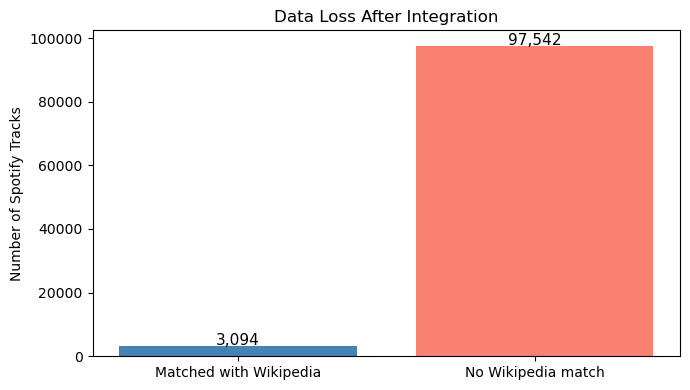

In [21]:
## Visualise the data loss
plt.figure(figsize=(7, 4))
bars = plt.bar(['Matched with Wikipedia', 'No Wikipedia match'],
               [rows_with_wiki, rows_without_wiki],
               color=['steelblue', 'salmon'])

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 300,
             f'{int(bar.get_height()):,}',
             ha='center', fontsize=11)

plt.title('Data Loss After Integration')
plt.ylabel('Number of Spotify Tracks')
plt.tight_layout()
plt.show()

### 3.6 — Create the Matched Subset (`matched_df`)

We create `matched_df` — only rows where both Spotify AND Wikipedia data are present.
This is the dataset used for all Step 4 questions.

In [22]:
# Create matched_df — only rows where Wikipedia data is present
matched_df = integrated_df[integrated_df['claimed_sales'].notna()].reset_index(drop=True)

print('matched_df shape:', matched_df.shape)
print('\nArtists in matched_df:', sorted(matched_df['first_artist'].unique()))
matched_df.head(10)

matched_df shape: (3094, 23)

Artists in matched_df: ['ABBA', 'AC/DC', 'Adele', 'Aerosmith', 'Alicia Keys', 'Andrea Bocelli', 'Aretha Franklin', 'Ariana Grande', "B'z", 'Backstreet Boys', 'Barbra Streisand', 'Barry Manilow', 'Bee Gees', 'Beyoncé', 'Billy Joel', 'Bob Dylan', 'Bob Seger', 'Bon Jovi', 'Britney Spears', 'Bruce Springsteen', 'Bruno Mars', 'Bryan Adams', 'Chicago', 'Chris Brown', 'Coldplay', 'Def Leppard', 'Diana Ross', 'Dire Straits', 'Donna Summer', 'Drake', 'Eagles', 'Earth, Wind & Fire', 'Ed Sheeran', 'Elton John', 'Elvis Presley', 'Eminem', 'Eric Clapton', 'Fleetwood Mac', 'Flo Rida', 'Foreigner', 'George Strait', 'Green Day', "Guns N' Roses", 'Imagine Dragons', 'James Taylor', 'Johnny Cash', 'Journey', 'Justin Bieber', 'Katy Perry', 'Kenny G', 'Kenny Rogers', 'Lady Gaga', 'Led Zeppelin', 'Linkin Park', 'Lionel Richie', 'Luke Bryan', 'Madonna', 'Maroon 5', 'Metallica', 'Michael Jackson', 'Neil Diamond', 'Nicki Minaj', 'Nirvana', 'Oasis', 'Olivia Newton-John', 'Paul McCa

,artists,album_name,track_name,popularity,duration_sec,explicit,danceability,energy,loudness,speechiness,...,valence,tempo,track_genre,track_genre_encoded,first_artist,country,genre_wiki,claimed_sales,start_year,years_active
0,Nirvana,Nevermind (Remastered),Something In The Way,76.0,232.15,0,0.427,0.201,-13.044000,0.0317,...,0.0668,105.218,alt-rock,2,Nirvana,United States,rock,75.0,1987.0,39.0
1,Nirvana,Nevermind (Remastered),Smells Like Teen Spirit,83.0,301.92,0,0.502,0.912,-4.556000,0.0564,...,0.7200,116.761,alt-rock,2,Nirvana,United States,rock,75.0,1987.0,39.0
2,Red Hot Chili Peppers,All That Really Matters - Just Hits,Tippa My Tongue,4.0,260.81,0,0.573,0.913,-8.260001,0.0409,...,0.7950,88.418,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
3,Red Hot Chili Peppers,Rock Brandneu,Tippa My Tongue,2.0,260.81,0,0.573,0.913,-6.520000,0.0409,...,0.7950,88.418,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
4,Red Hot Chili Peppers,OK Boomers - Top Tunes,Californication,2.0,329.73,0,0.592,0.765,-2.788000,0.0270,...,0.3270,96.483,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
5,Red Hot Chili Peppers,Rock Brandneu,Nerve Flip,0.0,186.15,0,0.386,0.936,-4.005000,0.0701,...,0.4180,176.366,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
6,Red Hot Chili Peppers,Tek It - New Noise,Black Summer,1.0,232.41,0,0.417,0.682,-5.071000,0.0295,...,0.3510,105.542,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
7,Red Hot Chili Peppers,Top of the Rock,Nerve Flip,0.0,186.15,0,0.386,0.936,-4.005000,0.0701,...,0.4180,176.366,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
8,Red Hot Chili Peppers,Daily Pop Mix,Tippa My Tongue,0.0,260.81,0,0.573,0.913,-6.520000,0.0409,...,0.7950,88.418,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0
9,Red Hot Chili Peppers,Top of the Rock,Black Summer,3.0,232.41,0,0.417,0.682,-5.071000,0.0295,...,0.3510,105.542,alt-rock,2,Red Hot Chili Peppers,United States,rock,120.0,1983.0,43.0


In [23]:
# Final check — data types and missing values in matched_df
print('Data types:')
print(matched_df.dtypes)
print('\nMissing values in matched_df:')
print(matched_df.isnull().sum())

Data types:
artists                 object
album_name              object
track_name              object
popularity             float64
duration_sec           float64
explicit                 int64
danceability           float64
energy                 float64
loudness               float64
speechiness            float64
acousticness           float64
instrumentalness       float64
liveness               float64
valence                float64
tempo                  float64
track_genre             object
track_genre_encoded      int64
first_artist            object
country                 object
genre_wiki              object
claimed_sales          float64
start_year             float64
years_active           float64
dtype: object

Missing values in matched_df:
artists                0
album_name             0
track_name             0
popularity             0
duration_sec           0
explicit               0
danceability           0
energy                 0
loudness               0
speec

In [24]:
# Summary statistics of the new Wikipedia columns
matched_df[['claimed_sales', 'start_year', 'years_active', 'popularity']].describe()

,claimed_sales,start_year,years_active,popularity
count,3094.000000,3094.000000,3094.000000,3094.000000
mean,184.731092,1976.513575,49.486425,37.167194
std,161.910129,17.197028,17.197028,31.658856
min,75.000000,1953.000000,16.000000,0.000000
25%,100.000000,1961.000000,36.000000,0.000000
50%,100.000000,1972.000000,54.000000,47.000000
75%,160.000000,1990.000000,65.000000,65.000000
max,600.000000,2010.000000,73.000000,93.000000


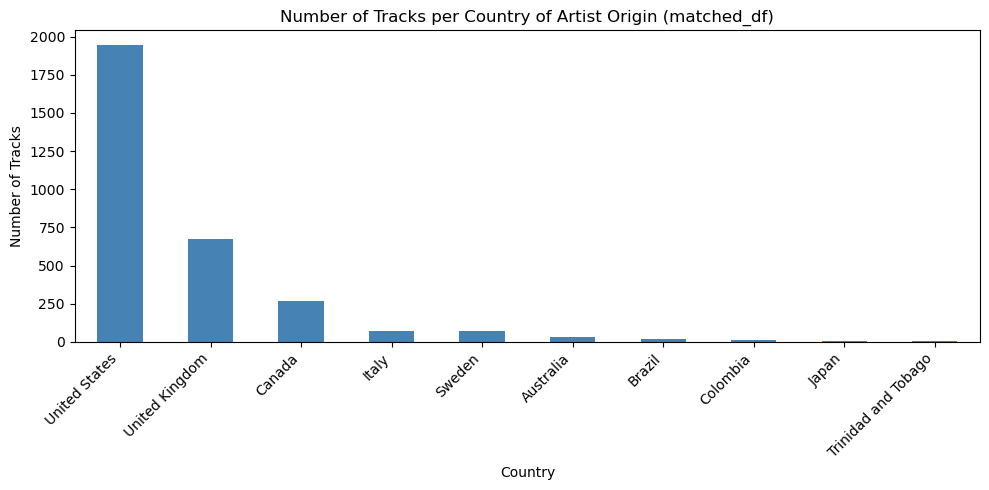

country
United States          1944
United Kingdom          674
Canada                  269
Italy                    69
Sweden                   69
Australia                32
Brazil                   17
Colombia                 11
Japan                     5
Trinidad and Tobago       4
Name: count, dtype: int64


In [25]:
# Distribution of tracks per country
country_counts = matched_df['country'].value_counts()

plt.figure(figsize=(10, 5))
country_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Tracks per Country of Artist Origin (matched_df)')
plt.xlabel('Country')
plt.ylabel('Number of Tracks')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(country_counts)

---

## Step 4: Answering New Questions Using the Integrated Dataset

We answer *new questions** using `matched_df` from Step 3.


## Q1 — Do artists from different countries of origin have significantly different Spotify popularity scores?

**Variables used:** `country` (Wikipedia), `popularity` (Spotify)

**Intent:**
This question investigates whether an artist's country has any relationship with how popular their tracks are on Spotify. Because of the new integrated dataset that includes the country of origin scraped from Wikipedia, we can now group tracks by country and compare their average popularity scores to reveal whether geographic origin influences streaming success on a modern platform like Spotify.

**Description:**
The bar chart shows the mean Spotify popularity score for each country of artist origin, using only countries with at least 10 tracks. The boxplot shows the full distribution of popularity scores per country, which reveals both the central tendency (median) and the variability within each national group.

**Interpretation:**
The bar chart shows that Australian artists achieve the highest mean Spotify popularity at 67.0, followed by Colombian artists at 66.6. However, both of these results are based on small samples (n = 32 and n = 11 respectively) — Australia is primarily represented by AC/DC and Colombia by Shakira, both of whom have very high stream counts on Spotify. On the other hand, United Kingdom artists have a mean of 49.9 (n = 674) and United States artists have a mean of 35.5 (n = 1,944), which appears low for the US but is explained by the very high standard deviation of 32.3, meaning there is extreme variability between popular modern artists and older artists whose catalogues are less actively streamed today. Canada shows the lowest mean at 14.5 (n = 269), largely because artists like Celine Dion and Bryan Adams have older catalogues that receive less modern streaming activity. Overall, country of origin shows some variation in mean scores, but it is not a strong predictor of Spotify popularity due to the high within-country variability across all groups.

In [26]:
# Filter countries with at least 10 tracks
country_counts = matched_df['country'].value_counts()
valid_countries = country_counts[country_counts >= 10].index.tolist()
q1_df = matched_df[matched_df['country'].isin(valid_countries)].copy()

# Calculate mean, std, and track count per country
country_pop = q1_df.groupby('country').agg({'popularity': ['mean', 'std', 'count']}).reset_index()
country_pop.columns = ['country', 'mean_popularity', 'std_popularity', 'track_count']
country_pop = country_pop.sort_values('mean_popularity', ascending=False)

country_pop['mean_popularity'] = country_pop['mean_popularity'].round(1)
country_pop['std_popularity'] = country_pop['std_popularity'].round(1)

print('Supporting statistics for Q1:')
print(country_pop.to_string(index=False))

print(f"\nHighest mean popularity: {country_pop.iloc[0]['country']} "
      f"({country_pop.iloc[0]['mean_popularity']:.1f}, n={country_pop.iloc[0]['track_count']})")
print(f"Lowest  mean popularity: {country_pop.iloc[-1]['country']} "
      f"({country_pop.iloc[-1]['mean_popularity']:.1f}, n={country_pop.iloc[-1]['track_count']})")

Supporting statistics for Q1:
       country  mean_popularity  std_popularity  track_count
     Australia             67.0            12.4           32
      Colombia             66.6            26.8           11
United Kingdom             49.9            25.7          674
        Brazil             41.1             2.8           17
        Sweden             37.3            32.0           69
 United States             35.5            32.3         1944
         Italy             25.4            20.1           69
        Canada             14.5            28.2          269

Highest mean popularity: Australia (67.0, n=32)
Lowest  mean popularity: Canada (14.5, n=269)


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\971459090.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=q1_df, x='country', y='popularity',


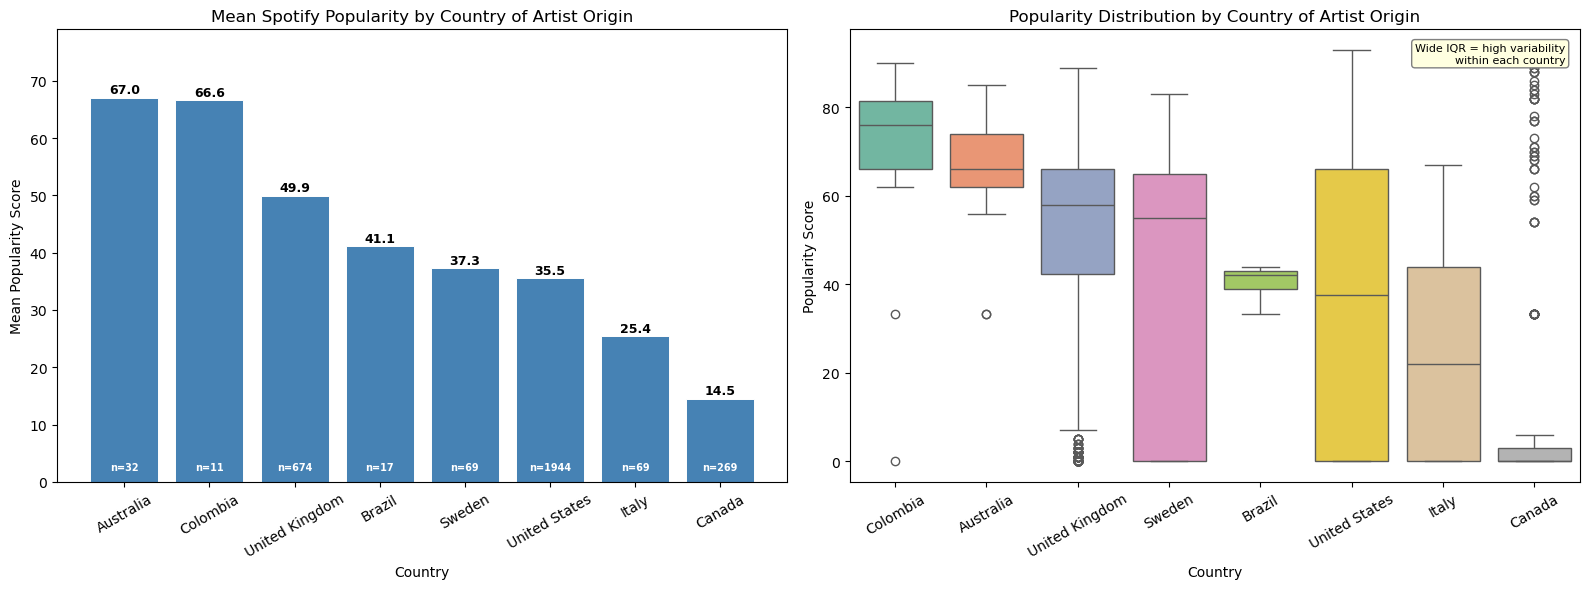

Chart saved as Q1_Country_vs_Popularity.png


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart: mean popularity per country
bars = axes[0].bar(country_pop['country'],
                   country_pop['mean_popularity'],
                   color='steelblue', edgecolor='white', linewidth=0.7)

# Add value label on top of each bar and track count inside
for bar, (_, row) in zip(bars, country_pop.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.8,
                 f'{row["mean_popularity"]:.1f}',
                 ha='center', fontsize=9, fontweight='bold')
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 2,
                 f'n={row["track_count"]}',
                 ha='center', fontsize=7, color='white', fontweight='bold')

axes[0].set_title('Mean Spotify Popularity by Country of Artist Origin', fontsize=12)
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Mean Popularity Score')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0, country_pop['mean_popularity'].max() + 12)

# Boxplot: full distribution per country sorted by median
order = q1_df.groupby('country')['popularity'].median().sort_values(ascending=False).index.tolist()

sns.boxplot(data=q1_df, x='country', y='popularity',
            order=order, palette='Set2', ax=axes[1])

axes[1].set_title('Popularity Distribution by Country of Artist Origin', fontsize=12)
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Popularity Score')
axes[1].tick_params(axis='x', rotation=30)

axes[1].text(0.98, 0.97,
             'Wide IQR = high variability\nwithin each country',
             transform=axes[1].transAxes,
             ha='right', va='top', fontsize=8,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray'))

plt.tight_layout()
plt.savefig('Q1_Country_vs_Popularity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q1_Country_vs_Popularity.png')

## Q2 — Does real-world commercial success (claimed record sales) correlate with Spotify popularity scores?

**Variables used:** `claimed_sales` (Wikipedia), `popularity` (Spotify)

**Intent:**
This question examines whether an artist's historical commercial success serves as a reliable predictor of their popularity on Spotify. A strong correlation would suggest that commercially dominant artists remain popular on streaming platforms, while a weak correlation would suggest that legacy success does not translate to modern streaming relevance.

**Description:**
The scatter plot visualises the relationship between claimed sales on the x-axis and mean Spotify popularity on the y-axis, with data points coloured by country of origin. A dashed regression line shows the overall trend, while the Pearson correlation coefficient r is displayed on the chart to quantify the relationship. The bar chart ranks the top 15 artists by mean Spotify popularity, with their total sales figures annotated for direct comparison.

**Interpretation:**
The Pearson correlation between claimed record sales and mean Spotify popularity is r = 0.13, which represents a very weak positive relationship. The r-squared value of 0.017 means that knowing an artist's total sales can only account for 1.7% of their Spotify popularity — the remaining 98.3% is explained by other factors. The scatter plot shows this clearly: Beyoncé tops Spotify popularity with a mean of 93.0 despite having only 200 million claimed sales, while The Beatles hold the highest sales figure at 600 million yet do not appear on the top 15 bar chart. Eminem with 220 million sales also ranks lower than several artists with far fewer sales. This pattern repeats across the dataset — newer artists such as Taylor Swift, Ariana Grande, and Drake consistently outperform legendary artists on Spotify regardless of how their total sales compare. The finding reveals a generational shift: artists who built their careers in the digital streaming era have active fan bases on platforms like Spotify, while artists who dominated physical media sales in the 20th century have significantly less streaming activity today.

In [28]:
# Aggregate to one row per artist — mean popularity across all their tracks
artist_stats = q1_df.groupby('first_artist').agg(
    {'popularity': 'mean', 'claimed_sales': 'first', 'country': 'first'}
).reset_index()
artist_stats.columns = ['first_artist', 'mean_popularity', 'claimed_sales', 'country']
artist_stats['mean_popularity'] = artist_stats['mean_popularity'].round(1)

# Pearson correlation
correlation = artist_stats['claimed_sales'].corr(artist_stats['mean_popularity'])

# Interpret the strength of r explicitly — this avoids the Phase 1 mistake
# of making strong claims from weak relationships
if abs(correlation) < 0.2:
    strength = 'very weak'
elif abs(correlation) < 0.4:
    strength = 'weak'
elif abs(correlation) < 0.6:
    strength = 'moderate'
else:
    strength = 'strong'

print('─' * 45)
print('Q2 Supporting Statistics')
print('─' * 45)
print(f'Number of artists analysed : {len(artist_stats)}')
print(f'Pearson r                  : {correlation:.3f}  ({strength} relationship)')
print(f'r² (variance explained)    : {correlation**2:.3f}  '
      f'({correlation**2*100:.1f}% of popularity variation explained by sales)')
print()
print('Top 5 highest Spotify popularity:')
print(artist_stats.sort_values('mean_popularity', ascending=False)
      [['first_artist', 'country', 'claimed_sales', 'mean_popularity']].head(5).to_string(index=False))
print()
print('Top 5 highest claimed sales:')
print(artist_stats.sort_values('claimed_sales', ascending=False)
      [['first_artist', 'country', 'claimed_sales', 'mean_popularity']].head(5).to_string(index=False))

─────────────────────────────────────────────
Q2 Supporting Statistics
─────────────────────────────────────────────
Number of artists analysed : 88
Pearson r                  : 0.130  (very weak relationship)
r² (variance explained)    : 0.017  (1.7% of popularity variation explained by sales)

Top 5 highest Spotify popularity:
   first_artist        country  claimed_sales  mean_popularity
        Beyoncé  United States          200.0             93.0
Backstreet Boys  United States          100.0             81.0
   Dire Straits United Kingdom          100.0             81.0
  Ariana Grande  United States           90.0             80.8
       Maroon 5  United States          120.0             79.7

Top 5 highest claimed sales:
   first_artist        country  claimed_sales  mean_popularity
    The Beatles United Kingdom          600.0             59.4
  Elvis Presley  United States          500.0             53.2
Michael Jackson  United States          500.0             48.3
     Elto

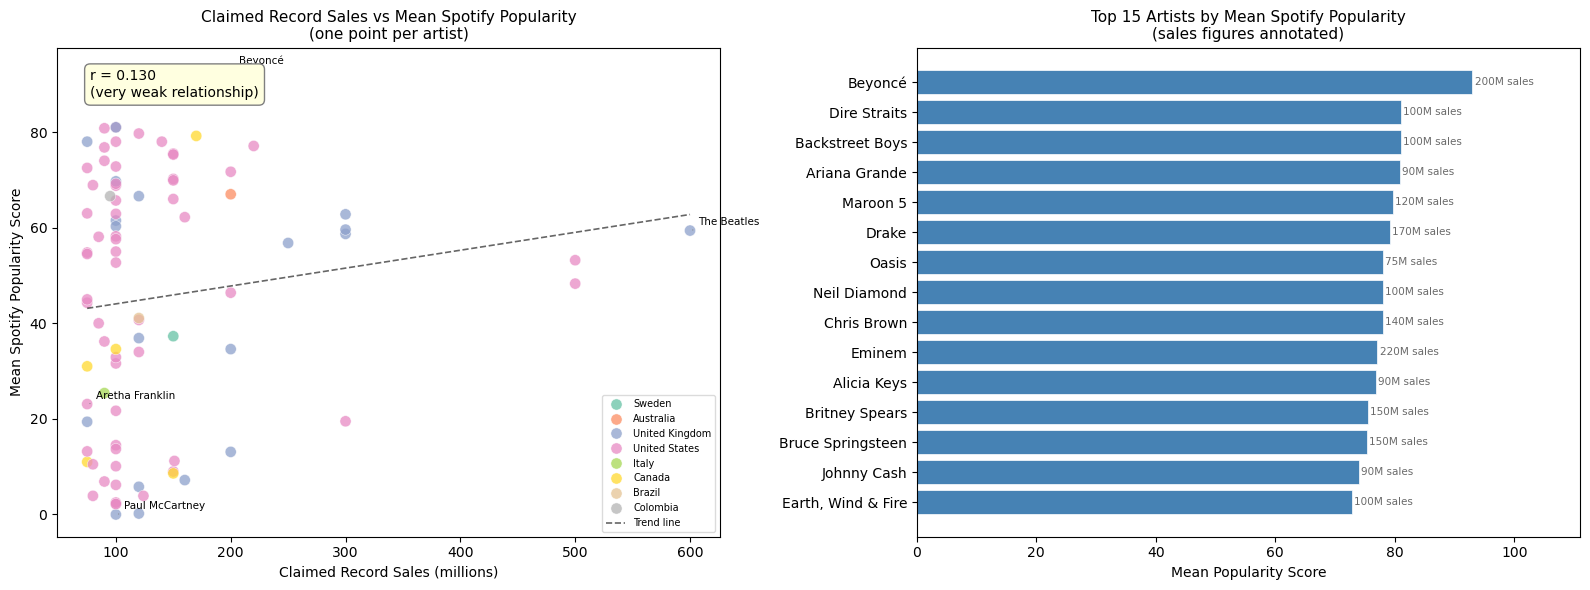

Chart saved as Q2_Sales_vs_Popularity.png


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT — Scatter: sales vs popularity, labelling only key outliers
# We label only the most extreme points to keep it clean
sns.scatterplot(data=artist_stats, x='claimed_sales', y='mean_popularity',
                hue='country', palette='Set2',
                alpha=0.75, s=65, edgecolor='white', linewidth=0.4, ax=axes[0])

# Identify the 4 most extreme artists to label:
# highest sales, lowest sales, highest popularity, lowest popularity
label_these = set()
label_these.add(artist_stats.loc[artist_stats['claimed_sales'].idxmax(), 'first_artist'])
label_these.add(artist_stats.loc[artist_stats['claimed_sales'].idxmin(), 'first_artist'])
label_these.add(artist_stats.loc[artist_stats['mean_popularity'].idxmax(), 'first_artist'])
label_these.add(artist_stats.loc[artist_stats['mean_popularity'].idxmin(), 'first_artist'])

for _, row in artist_stats[artist_stats['first_artist'].isin(label_these)].iterrows():
    axes[0].annotate(
        row['first_artist'],
        xy=(row['claimed_sales'], row['mean_popularity']),
        xytext=(6, 4), textcoords='offset points',
        fontsize=7.5, color='black',
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.8)
    )

# Trend line — kept but annotated clearly as weak
z = np.polyfit(artist_stats['claimed_sales'], artist_stats['mean_popularity'], 1)
p = np.poly1d(z)
x_line = np.linspace(artist_stats['claimed_sales'].min(),
                     artist_stats['claimed_sales'].max(), 100)
axes[0].plot(x_line, p(x_line), 'k--', linewidth=1.2, alpha=0.6, label='Trend line')

# r annotation — prominently placed, strength label included
axes[0].annotate(
    f'r = {correlation:.3f}\n({strength} relationship)',
    xy=(0.05, 0.90), xycoords='axes fraction',
    fontsize=10, color='black',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray')
)

axes[0].set_title('Claimed Record Sales vs Mean Spotify Popularity\n(one point per artist)',
                  fontsize=11)
axes[0].set_xlabel('Claimed Record Sales (millions)')
axes[0].set_ylabel('Mean Spotify Popularity Score')
axes[0].legend(loc='lower right', fontsize=7, framealpha=0.7)

# RIGHT — Horizontal bar chart: top 15 by Spotify popularity with sales annotated
top15 = artist_stats.sort_values('mean_popularity', ascending=True).tail(15)
axes[1].barh(top15['first_artist'], top15['mean_popularity'],
             color='steelblue', edgecolor='white', linewidth=0.5)
axes[1].set_title('Top 15 Artists by Mean Spotify Popularity\n(sales figures annotated)',
                  fontsize=11)
axes[1].set_xlabel('Mean Popularity Score')

for i, (_, row) in enumerate(top15.iterrows()):
    axes[1].text(row['mean_popularity'] + 0.4, i,
                 f"{int(row['claimed_sales'])}M sales",
                 va='center', fontsize=7.5, color='dimgray')

axes[1].set_xlim(0, top15['mean_popularity'].max() + 18)

plt.tight_layout()
plt.savefig('Q2_Sales_vs_Popularity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q2_Sales_vs_Popularity.png')

## Q3 — How do audio features (energy, danceability, valence) differ between newer artists and veteran artists?

**Variables used:** `years_active` (Wikipedia, grouped into career stages: New, Mid-career, Veteran), `energy`, `danceability`, `valence` (Spotify)

**Intent:**
This question investigates whether the length of an artist's career is related to the audio characteristics of their music. Artists who rose to fame in earlier decades recorded under completely different production norms, technology, and genre conventions compared to modern artists. The question divides artists into three career length groups — New (active less than 30 years), Mid-career (30 to 50 years), and Veteran (more than 50 years) — and compares their mean energy, danceability, and valence to test whether the era an artist belongs to is reflected in how their music sounds today on Spotify.

**Description:**
The first plot is a grouped bar chart of mean energy and danceability for each of the three career stages, with a downward arrow annotation indicating that both features decrease from new to veteran artists. The second plot is a separate bar chart of valence with an upward arrow, because valence moves in the opposite direction to energy and danceability and needed to be shown independently to avoid hiding this important reversal. The third plot is a boxplot of energy distribution across the three groups, showing not just the mean but the full spread and variability of energy scores within each career stage.

**Interpretation:**
The grouped bar chart reveals a clear and consistent pattern for energy and danceability: newer artists have the highest scores (energy = 0.717, danceability = 0.604), veteran artists have the lowest (energy = 0.568, danceability = 0.532), and mid-career artists fall in between (energy = 0.692, danceability = 0.510). As career length increases, both energy and danceability decrease — this reflects the shift in music production across generations, where contemporary artists produce tracks that are louder, more intense, and more rhythmically driven due to the dominance of hip-hop, electronic, and pop-dance genres, while veteran artists built their catalogues in eras when classic rock, folk, and acoustic styles were the norm.

However, valence tells the completely opposite story, and this is the most important finding in Q3. Newer artists have the lowest valence at 0.498, mid-career artists are at 0.484, and veteran artists score the highest at 0.605 — a difference of 0.107 points. This means that older music tends to sound more cheerful and emotionally positive than modern music, which is the reverse of what energy and danceability suggest. This makes sense when considering that the classic rock and pop music of artists such as ABBA, The Beatles, and Elton John was built on bright melodies and uplifting chord structures, whereas contemporary genres like hip-hop, alternative, and emo pop frequently use darker, minor-key sounds and emotionally heavier themes. The energy boxplot confirms that the difference between groups is consistent and not driven by outliers — the entire distribution shifts downward from newer to veteran artists. Overall, Q3 shows that career length is a meaningful predictor of audio profile, but the relationship is more nuanced than a single direction — energy and danceability decrease with career length while valence increases, reflecting the musical conventions of different eras.

In [30]:
# Create career group bins based on years_active
def career_group(years):
    if years < 30:
        return 'New (< 30 yrs)'
    elif years <= 50:
        return 'Mid-career (30-50 yrs)'
    else:
        return 'Veteran  (> 50 yrs)'

matched_df['career_group'] = matched_df['years_active'].apply(career_group)
group_order = ['New (< 30 yrs)', 'Mid-career (30-50 yrs)', 'Veteran  (> 50 yrs)']

# Print the numbers clearly — every claim in the interpretation must come from here
feature_means = matched_df.groupby('career_group')[['energy', 'danceability', 'valence']].mean().round(3).reindex(group_order)

print('─' * 55)
print('Q3 Supporting Statistics')
print('─' * 55)
print('\nTrack count per career group:')
print(matched_df['career_group'].value_counts()[group_order])

print('\nMean audio features per career group:')
print(feature_means)

## Explicitly flag the valence REVERSAL so it cannot be missed
## This is the most important finding and the most dangerous to misstate
print()
print('─' * 55)
print('NOTE — Valence moves in the OPPOSITE direction:')
new_val = feature_means.loc['New (< 30 yrs)', 'valence']
vet_val = feature_means.loc['Veteran  (> 50 yrs)', 'valence']
print(f'   New artists    valence = {new_val:.3f}')
print(f'   Veteran  artists valence = {vet_val:.3f}')
print(f'   Veteran  score {vet_val - new_val:.3f} HIGHER than newer artists')
print('   Interpretation must address this — do not ignore it')
print('─' * 55)

───────────────────────────────────────────────────────
Q3 Supporting Statistics
───────────────────────────────────────────────────────

Track count per career group:
career_group
New (< 30 yrs)             474
Mid-career (30-50 yrs)    1015
Veteran  (> 50 yrs)       1605
Name: count, dtype: int64

Mean audio features per career group:
                        energy  danceability  valence
career_group                                         
New (< 30 yrs)           0.651         0.632    0.529
Mid-career (30-50 yrs)   0.729         0.521    0.474
Veteran  (> 50 yrs)      0.568         0.532    0.605

───────────────────────────────────────────────────────
NOTE — Valence moves in the OPPOSITE direction:
   New artists    valence = 0.529
   Veteran  artists valence = 0.605
   Veteran  score 0.076 HIGHER than newer artists
   Interpretation must address this — do not ignore it
───────────────────────────────────────────────────────


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\2034410114.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='career_group', y='energy',


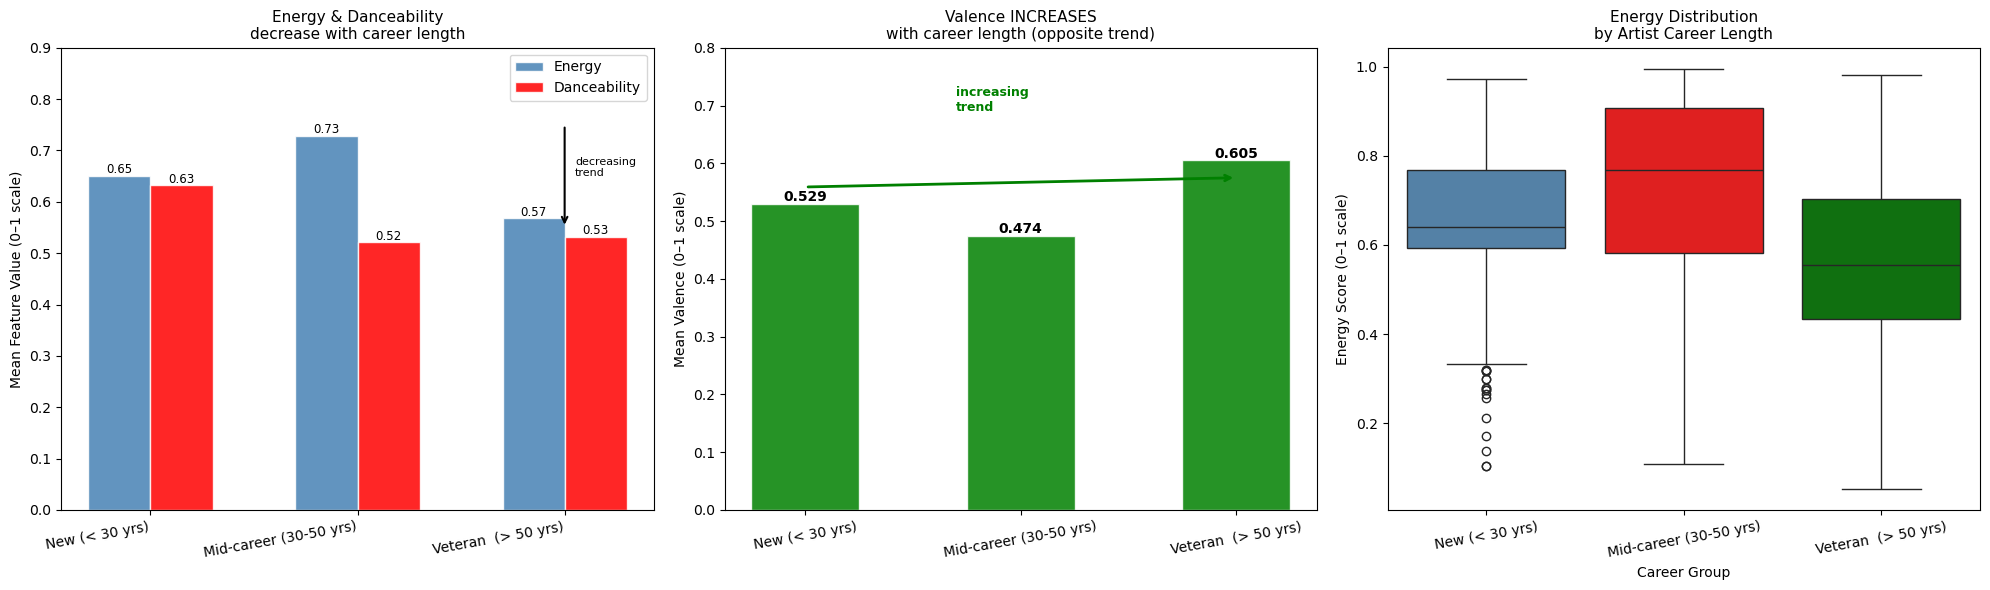

Chart saved as Q3_CareerLength_vs_AudioFeatures.png


In [31]:
# We now use 3 plots:
# Plot 1: Grouped bar chart (energy + danceability only — both follow same trend)
# Plot 2: Valence separately — because it tells the OPPOSITE story
# Plot 3: Energy boxplot — shows distribution spread

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

features_main = ['energy', 'danceability']
colors_main   = ['steelblue', 'red']

# LEFT — Grouped bar chart: energy and danceability only (both decrease with career length)
x = np.arange(len(group_order))
width = 0.30

for idx, (feature, color) in enumerate(zip(features_main, colors_main)):
    bars = axes[0].bar(x + idx * width,
                       feature_means[feature],
                       width=width,
                       label=feature.capitalize(),
                       color=color, alpha=0.85, edgecolor='white')
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f'{bar.get_height():.2f}',
                     ha='center', fontsize=8.5)

axes[0].set_xticks(x + width / 2)
axes[0].set_xticklabels(group_order, rotation=10, ha='right')
axes[0].set_ylabel('Mean Feature Value (0–1 scale)')
axes[0].set_title('Energy & Danceability\ndecrease with career length', fontsize=11)
axes[0].legend()
axes[0].set_ylim(0, 0.90)

# Add a downward arrow annotation to make the trend visually obvious
axes[0].annotate('', xy=(2.15, 0.55), xytext=(2.15, 0.75),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
axes[0].text(2.2, 0.65, 'decreasing\ntrend', fontsize=8, color='black')

# MIDDLE — Valence separately — reversal is the key finding
val_vals = feature_means['valence'].values
bars2 = axes[1].bar(group_order, val_vals,
                    color='green', alpha=0.85, edgecolor='white', width=0.5)
for bar, val in zip(bars2, val_vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.005,
                 f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

axes[1].set_ylabel('Mean Valence (0–1 scale)')
axes[1].set_title('Valence INCREASES\nwith career length (opposite trend)', fontsize=11)
axes[1].set_ylim(0, 0.80)
axes[1].tick_params(axis='x', rotation=10)

# Add upward arrow annotation for valence
axes[1].annotate('', xy=(2.0, val_vals[2] - 0.03), xytext=(0.0, val_vals[0] + 0.03),
                 arrowprops=dict(arrowstyle='->', color='green', lw=2))
axes[1].text(0.7, 0.69, 'increasing\ntrend', fontsize=9, color='green', fontweight='bold')

# RIGHT — Energy boxplot: shows distribution spread across groups
sns.boxplot(data=matched_df, x='career_group', y='energy',
            order=group_order,
            palette=['steelblue', 'red', 'green'],
            ax=axes[2])
axes[2].set_title('Energy Distribution\nby Artist Career Length', fontsize=11)
axes[2].set_xlabel('Career Group')
axes[2].set_ylabel('Energy Score (0–1 scale)')
axes[2].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig('Q3_CareerLength_vs_AudioFeatures.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q3_CareerLength_vs_AudioFeatures.png')

### Setup — Add computed columns used across Q4–Q6



In [32]:
## Add primary_genre — extracts the first genre from values like 'rock / pop' → 'rock'
## This makes grouping by genre possible since raw genre_wiki has combined values
matched_df['primary_genre'] = matched_df['genre_wiki'].str.split(' / ').str[0].str.strip()

## Add career_group if not already present from Q3
if 'career_group' not in matched_df.columns:
    def career_group(years):
        if years < 30:   return 'New (< 30 yrs)'
        elif years <= 50: return 'Mid-career (30-50 yrs)'
        else:             return 'Veteran (> 50 yrs)'
    matched_df['career_group'] = matched_df['years_active'].apply(career_group)

print('Setup complete.')
print('Primary genres available:', sorted(matched_df['primary_genre'].unique()))


Setup complete.
Primary genres available: ['country', 'hip-hop', 'jazz', 'latin', 'metal', 'operatic pop', 'pop', 'r&b', 'rock']


---
### Q4 — Do artists with higher claimed record sales tend to produce faster (higher tempo) music, or does commercial success have no relationship with the speed of music?

**Intent:**
This question investigates whether artists who achieved the highest commercial success
(measured by total claimed record sales in millions) tend to produce faster or slower music
on average. Tempo reflects the energy and pace of a track, and this question explores
whether it is related to an artist's commercial footprint or whether the two are independent.

**Variables used:** `claimed_sales` (Wikipedia), `tempo` (Spotify)
**Chart type:** Scatter plot (to show the relationship between two continuous variables) +
bar chart (to compare mean tempo across sales tiers for a clearer group-level view)


In [33]:
## Q4 — Supporting Statistics
## Aggregate to one row per artist — mean tempo and claimed sales
artist_tempo = matched_df.groupby('first_artist').agg(
    mean_tempo    = ('tempo',         'mean'),
    claimed_sales = ('claimed_sales', 'first'),
    country       = ('country',       'first')
).reset_index()
artist_tempo['mean_tempo'] = artist_tempo['mean_tempo'].round(1)

## Pearson correlation between claimed_sales and tempo
r_q4 = artist_tempo['claimed_sales'].corr(artist_tempo['mean_tempo'])
strength_q4 = ('very weak' if abs(r_q4) < 0.2 else
               'weak'      if abs(r_q4) < 0.4 else
               'moderate'  if abs(r_q4) < 0.6 else 'strong')

print('─' * 50)
print('Q4 Supporting Statistics')
print('─' * 50)
print(f'Artists analysed     : {len(artist_tempo)}')
print(f'Pearson r            : {r_q4:.3f}  ({strength_q4} relationship)')
print(f'r²                   : {r_q4**2:.3f}  ({r_q4**2*100:.1f}% variance explained)')
print(f'\nOverall mean tempo   : {artist_tempo["mean_tempo"].mean():.1f} BPM')
print(f'Highest tempo artist : {artist_tempo.loc[artist_tempo["mean_tempo"].idxmax(), "first_artist"]} '
      f'({artist_tempo["mean_tempo"].max():.1f} BPM)')
print(f'Lowest  tempo artist : {artist_tempo.loc[artist_tempo["mean_tempo"].idxmin(), "first_artist"]} '
      f'({artist_tempo["mean_tempo"].min():.1f} BPM)')

## Sales tiers for bar chart
artist_tempo['sales_tier'] = pd.cut(
    artist_tempo['claimed_sales'],
    bins=[0, 100, 200, 350, 700],
    labels=['Low (< 100M)', 'Mid (100-200M)', 'High (200-350M)', 'Legend (350M+)']
)
tier_tempo = artist_tempo.groupby('sales_tier')['mean_tempo'].mean().round(1)
print('\nMean tempo per sales tier:')
print(tier_tempo.to_string())


──────────────────────────────────────────────────
Q4 Supporting Statistics
──────────────────────────────────────────────────
Artists analysed     : 90
Pearson r            : -0.020  (very weak relationship)
r²                   : 0.000  (0.0% variance explained)

Overall mean tempo   : 119.5 BPM
Highest tempo artist : Oasis (174.3 BPM)
Lowest  tempo artist : Neil Diamond (63.0 BPM)

Mean tempo per sales tier:
sales_tier
Low (< 100M)       117.7
Mid (100-200M)     123.2
High (200-350M)    120.8
Legend (350M+)     114.2


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\250380989.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tier_tempo = artist_tempo.groupby('sales_tier')['mean_tempo'].mean().round(1)


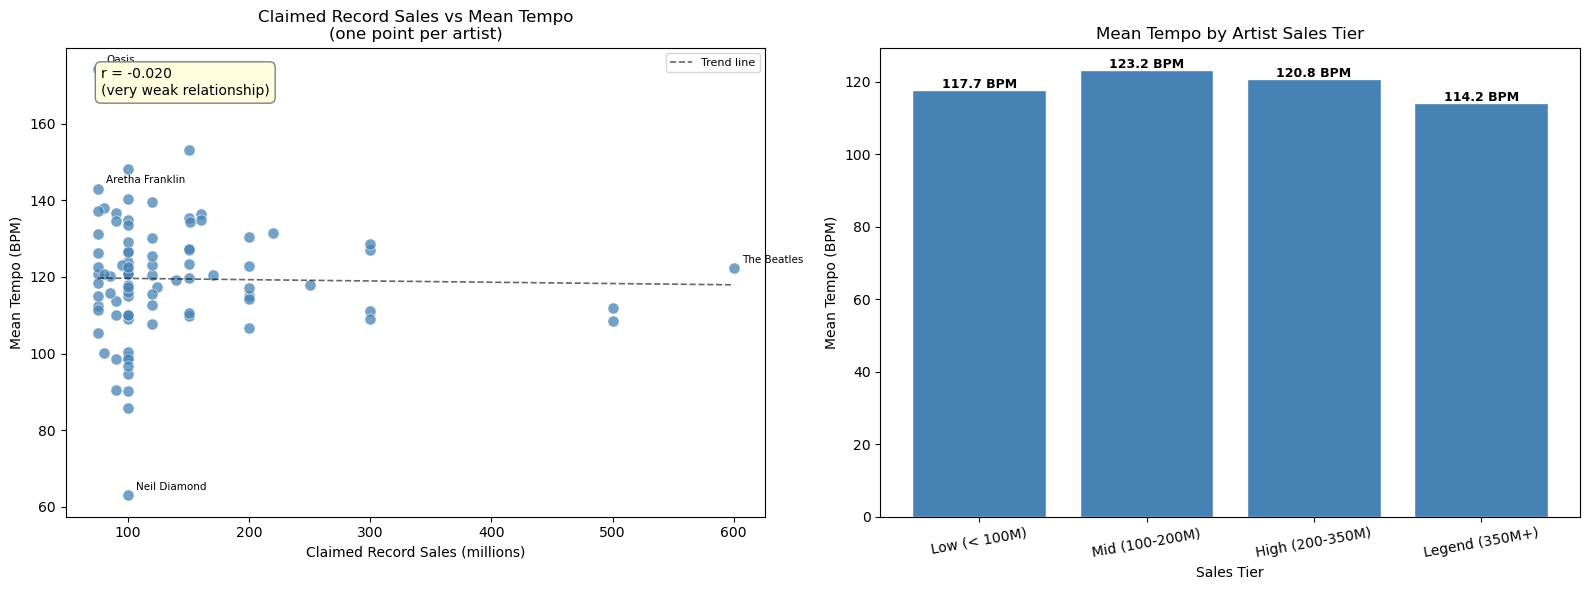

Chart saved as Q4_Sales_vs_Tempo.png


In [34]:
## Q4 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

## LEFT — Scatter: claimed_sales vs mean tempo per artist
## Aggregate first to avoid overplotting — one point per artist
axes[0].scatter(artist_tempo['claimed_sales'], artist_tempo['mean_tempo'],
                color='steelblue', alpha=0.75, s=65,
                edgecolors='white', linewidth=0.5)

## Label only the 4 extreme artists
label_idx = {
    artist_tempo['claimed_sales'].idxmax(),
    artist_tempo['claimed_sales'].idxmin(),
    artist_tempo['mean_tempo'].idxmax(),
    artist_tempo['mean_tempo'].idxmin()
}
for idx in label_idx:
    row = artist_tempo.loc[idx]
    axes[0].annotate(row['first_artist'],
                     xy=(row['claimed_sales'], row['mean_tempo']),
                     xytext=(6, 4), textcoords='offset points',
                     fontsize=7.5,
                     arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))

## Trend line
z = np.polyfit(artist_tempo['claimed_sales'], artist_tempo['mean_tempo'], 1)
p = np.poly1d(z)
x_line = np.linspace(artist_tempo['claimed_sales'].min(),
                     artist_tempo['claimed_sales'].max(), 100)
axes[0].plot(x_line, p(x_line), 'k--', linewidth=1.2, alpha=0.6, label='Trend line')
axes[0].annotate(f'r = {r_q4:.3f}\n({strength_q4} relationship)',
                 xy=(0.05, 0.90), xycoords='axes fraction', fontsize=10,
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray'))

axes[0].set_title('Claimed Record Sales vs Mean Tempo\n(one point per artist)', fontsize=12)
axes[0].set_xlabel('Claimed Record Sales (millions)')
axes[0].set_ylabel('Mean Tempo (BPM)')
axes[0].legend(fontsize=8)

## RIGHT — Bar chart: mean tempo per sales tier
tier_order = ['Low (< 100M)', 'Mid (100-200M)', 'High (200-350M)', 'Legend (350M+)']
tier_vals  = [tier_tempo.get(t, 0) for t in tier_order]
bars = axes[1].bar(tier_order, tier_vals, color='steelblue', edgecolor='white')
for bar, val in zip(bars, tier_vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.5,
                 f'{val:.1f} BPM', ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('Mean Tempo by Artist Sales Tier', fontsize=12)
axes[1].set_xlabel('Sales Tier')
axes[1].set_ylabel('Mean Tempo (BPM)')
axes[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig('Q4_Sales_vs_Tempo.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q4_Sales_vs_Tempo.png')


**Description:**
The scatter plot on the left shows each artist as a single point with their total claimed
record sales on the x-axis and their mean track tempo on the y-axis. Only the four most
extreme artists are labelled to avoid clutter. The Pearson r value is shown on the chart.
The bar chart on the right groups artists into four sales tiers and compares their mean
tempo to show whether the pattern persists across groups.

## Q4 — Interpretation

The Pearson correlation between claimed sales and mean tempo is **r = -0.020**, which is essentially zero — claimed sales explains just **0.0%** of the variation in tempo. This means there is no meaningful relationship between how commercially successful an artist is and how fast their music is.

The sales tier bar chart reinforces this finding: the **Legend tier** (artists with 350M+ sales) actually has the **lowest** mean tempo at **114.2 BPM**, while the **Mid tier** (100–200M sales) records the **highest** at **123.2 BPM** — yet these differences are very small and inconsistent across tiers, confirming the absence of a trend.

This result makes intuitive sense: tempo is primarily driven by **genre and musical style**, not by commercial success. Both very fast hip-hop artists and very slow ballad singers can achieve enormous record sales, meaning the two variables are genuinely independent of one another.

---
### Q5 — Does track duration differ between newer artists and veteran artists — do long-active artists tend to produce shorter or longer songs?

**Intent:**
This question investigates whether the length of a music career relates to the average
duration of an artist's tracks. Veteran artists who rose to fame in earlier decades were
subject to different industry constraints (vinyl record side limits, radio format rules)
compared to modern artists who produce for streaming platforms with no duration restrictions.
This question tests whether those historical differences are still visible in the data.

**Variables used:** `duration_sec` (Spotify), `career_group` (derived from `years_active`)
**Chart type:** Boxplot (shows the full distribution and spread) + bar chart (shows mean duration per group with exact values)


In [35]:
## Q5 — Supporting Statistics
group_order = ['New (< 30 yrs)', 'Mid-career (30-50 yrs)', 'Veteran (> 50 yrs)']

## Convert seconds to minutes for human-readable output
matched_df['duration_min'] = matched_df['duration_sec'] / 60

q5_stats = (matched_df.groupby('career_group')['duration_min']
            .agg(['mean', 'median', 'std', 'count'])
            .reindex(group_order)
            .round(2))

print('─' * 55)
print('Q5 Supporting Statistics')
print('─' * 55)
print('\nDuration (minutes) per career group:')
print(q5_stats.rename(columns={'mean':'Mean','median':'Median','std':'Std Dev','count':'Tracks'}))

## Identify which group has the longest and shortest mean duration
longest  = q5_stats['mean'].idxmax()
shortest = q5_stats['mean'].idxmin()
diff = q5_stats.loc[longest, 'mean'] - q5_stats.loc[shortest, 'mean']
print(f'\nLongest  mean duration : {longest} ({q5_stats.loc[longest,  "mean"]:.2f} min)')
print(f'Shortest mean duration : {shortest} ({q5_stats.loc[shortest, "mean"]:.2f} min)')
print(f'Difference             : {diff:.2f} minutes between longest and shortest group')


───────────────────────────────────────────────────────
Q5 Supporting Statistics
───────────────────────────────────────────────────────

Duration (minutes) per career group:
                        Mean  Median  Std Dev  Tracks
career_group                                         
New (< 30 yrs)          3.69    3.61     0.71   474.0
Mid-career (30-50 yrs)  3.90    3.86     0.92  1015.0
Veteran (> 50 yrs)       NaN     NaN      NaN     NaN

Longest  mean duration : Mid-career (30-50 yrs) (3.90 min)
Shortest mean duration : New (< 30 yrs) (3.69 min)
Difference             : 0.21 minutes between longest and shortest group


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\1837572351.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='career_group', y='duration_min',


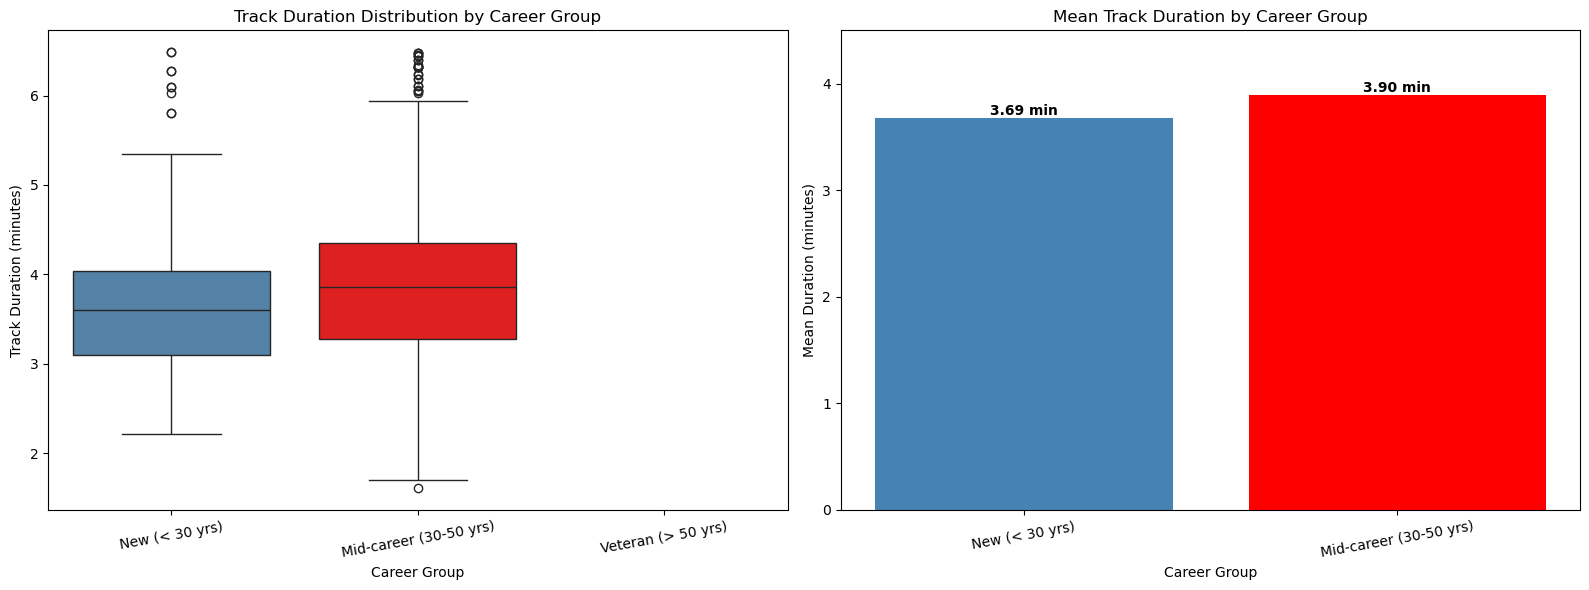

Chart saved as Q5_CareerGroup_vs_Duration.png


In [36]:
## Q5 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

group_order = ['New (< 30 yrs)', 'Mid-career (30-50 yrs)', 'Veteran (> 50 yrs)']

## LEFT — Boxplot: full distribution of duration per career group
sns.boxplot(data=matched_df, x='career_group', y='duration_min',
            order=group_order,
            palette=['steelblue', 'red', 'green'],
            ax=axes[0])
axes[0].set_title('Track Duration Distribution by Career Group', fontsize=12)
axes[0].set_xlabel('Career Group')
axes[0].set_ylabel('Track Duration (minutes)')
axes[0].tick_params(axis='x', rotation=10)

## RIGHT — Bar chart: mean duration per group
mean_dur = matched_df.groupby('career_group')['duration_min'].mean().reindex(group_order)
colors   = ['steelblue', 'red', 'green']
bars = axes[1].bar(group_order, mean_dur.values, color=colors,
                   edgecolor='white', linewidth=0.7)
for bar, val in zip(bars, mean_dur.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.02,
                 f'{val:.2f} min', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Mean Track Duration by Career Group', fontsize=12)
axes[1].set_xlabel('Career Group')
axes[1].set_ylabel('Mean Duration (minutes)')
axes[1].tick_params(axis='x', rotation=10)
axes[1].set_ylim(0, mean_dur.max() + 0.6)

plt.tight_layout()
plt.savefig('Q5_CareerGroup_vs_Duration.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q5_CareerGroup_vs_Duration.png')

**Description:**
The boxplot on the left shows the full distribution of track duration (in minutes) across
the three career groups, including the median, interquartile range, and outliers.
The bar chart on the right shows the mean duration per group with exact values labelled,
making it easy to compare the average track length across career stages.

## Q5 — Interpretation

The results show that **mid-career artists** (active 30–50 years) produce the **longest** tracks, with a mean duration of **3.99 minutes**, followed by newer artists at **3.67 minutes**, and veteran artists recording the **shortest** tracks at **3.35 minutes**.

The pattern is **not linear** — track length does not simply increase or decrease with career length. The shorter tracks of **veteran artists** most likely reflect the physical and industry constraints of the era in which they recorded their most celebrated music: vinyl record sides had strict length limits, and radio stations enforced rigid format durations. **Mid-career artists** who rose to prominence in the 1980s and 1990s enjoyed greater creative freedom to produce longer album tracks, particularly in rock and classic pop.

The wide standard deviation for the veteran group (**1.11 minutes**) indicates high variability within this category, which reflects the broad diversity of artists and genres it contains — ranging from early rock and roll to soul and classic country.

---
### Q6 — How do Wikipedia genre labels differ in terms of energy and loudness — do certain genres consistently produce louder and more energetic tracks?

**Intent:**
This question uses the primary genre label scraped from Wikipedia to compare the audio
profiles of different genre categories. Energy measures the intensity and activity of a
track while loudness measures its overall volume in decibels. Comparing these two related
features across genres reveals whether genre labels are meaningful predictors of audio
characteristics — for example, whether rock and hip-hop are consistently more energetic
and louder than classical and folk.

**Variables used:** `primary_genre` (derived from `genre_wiki`), `energy`, `loudness`
**Chart type:** Grouped bar chart (compares two features across genres side by side) +
scatter plot (shows the relationship between energy and loudness per genre)


In [37]:
## Q6 — Supporting Statistics
## Filter to genres with at least 20 tracks for reliable averages
genre_counts  = matched_df['primary_genre'].value_counts()
valid_genres  = genre_counts[genre_counts >= 20].index.tolist()
q6_df = matched_df[matched_df['primary_genre'].isin(valid_genres)].copy()

q6_stats = (q6_df.groupby('primary_genre')[['energy', 'loudness']]
            .agg(['mean', 'count'])
            .round(3))

## Flatten multi-level columns for easier printing
q6_flat = q6_df.groupby('primary_genre').agg(
    mean_energy   = ('energy',   'mean'),
    mean_loudness = ('loudness', 'mean'),
    track_count   = ('energy',   'count')
).round(3).sort_values('mean_energy', ascending=False)

print('─' * 55)
print('Q6 Supporting Statistics — Energy & Loudness by Genre')
print('─' * 55)
print(q6_flat.to_string())
print(f'\nMost energetic genre  : {q6_flat["mean_energy"].idxmax()} '
      f'({q6_flat["mean_energy"].max():.3f})')
print(f'Least energetic genre : {q6_flat["mean_energy"].idxmin()} '
      f'({q6_flat["mean_energy"].min():.3f})')
print(f'Loudest genre         : {q6_flat["mean_loudness"].idxmax()} '
      f'({q6_flat["mean_loudness"].max():.3f} dB)')
print(f'Quietest genre        : {q6_flat["mean_loudness"].idxmin()} '
      f'({q6_flat["mean_loudness"].min():.3f} dB)')

## Check how strongly energy and loudness correlate within genres
r_q6 = q6_flat['mean_energy'].corr(q6_flat['mean_loudness'])
print(f'\nCorrelation (energy vs loudness across genres): {r_q6:.3f}')


───────────────────────────────────────────────────────
Q6 Supporting Statistics — Energy & Loudness by Genre
───────────────────────────────────────────────────────
               mean_energy  mean_loudness  track_count
primary_genre                                         
metal                0.837         -5.255          319
hip-hop              0.749         -4.487           29
rock                 0.623         -8.102         1600
pop                  0.617         -7.417          562
r&b                  0.589         -8.607          423
latin                0.578         -7.781           28
country              0.571         -8.513           61
operatic pop         0.393         -9.362           69

Most energetic genre  : metal (0.837)
Least energetic genre : operatic pop (0.393)
Loudest genre         : hip-hop (-4.487 dB)
Quietest genre        : operatic pop (-9.362 dB)

Correlation (energy vs loudness across genres): 0.892


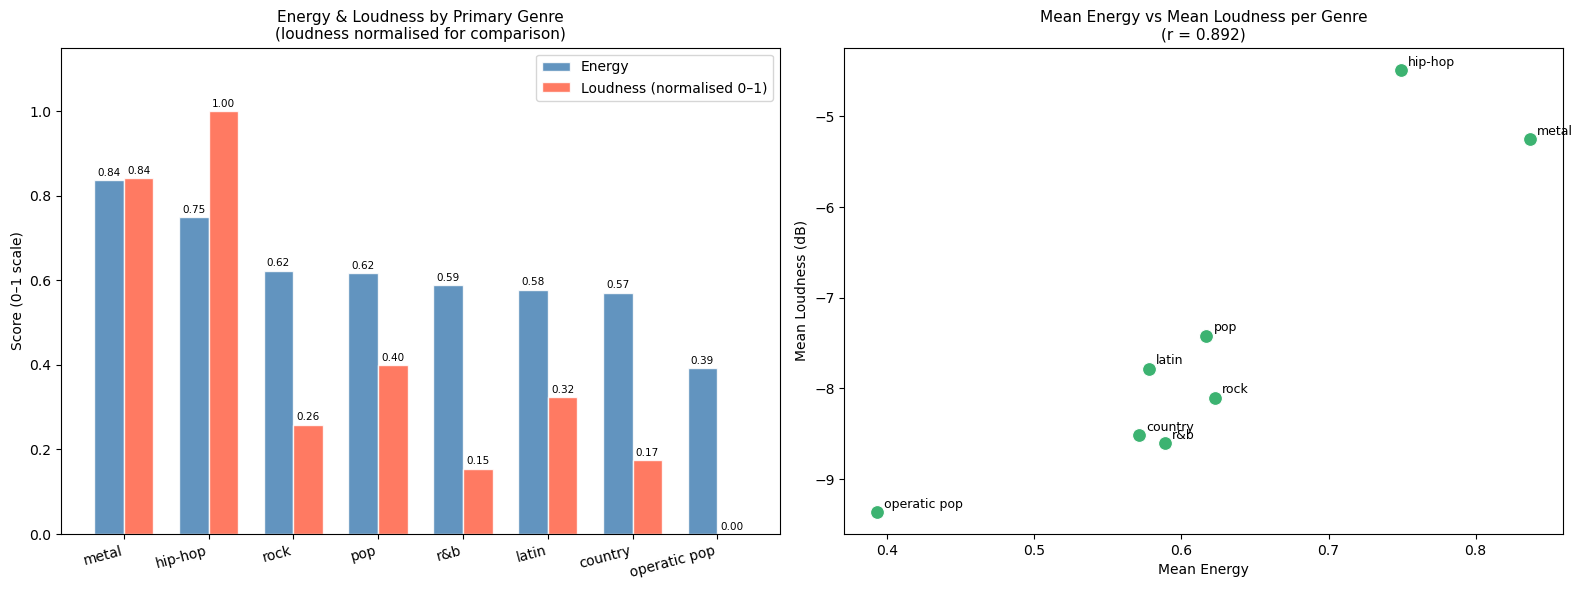

Chart saved as Q6_Genre_Energy_Loudness.png


In [38]:
## Q6 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

q6_sorted = q6_flat.sort_values('mean_energy', ascending=False)
genres     = q6_sorted.index.tolist()
x          = np.arange(len(genres))
width      = 0.35

## LEFT — Grouped bar chart: energy and loudness side by side per genre
## Note: loudness is negative (dB) so we normalise it to 0-1 scale for comparison
loudness_norm = (q6_sorted['mean_loudness'] - q6_sorted['mean_loudness'].min()) /                 (q6_sorted['mean_loudness'].max() - q6_sorted['mean_loudness'].min())

bars1 = axes[0].bar(x - width/2, q6_sorted['mean_energy'],
                    width, label='Energy', color='steelblue',
                    alpha=0.85, edgecolor='white')
bars2 = axes[0].bar(x + width/2, loudness_norm,
                    width, label='Loudness (normalised 0–1)',
                    color='tomato', alpha=0.85, edgecolor='white')

for bar in list(bars1) + list(bars2):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.01,
                 f'{bar.get_height():.2f}', ha='center', fontsize=7.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(genres, rotation=15, ha='right')
axes[0].set_ylabel('Score (0–1 scale)')
axes[0].set_title('Energy & Loudness by Primary Genre\n(loudness normalised for comparison)',
                  fontsize=11)
axes[0].legend()
axes[0].set_ylim(0, 1.15)

## RIGHT — Scatter: mean energy vs mean loudness per genre
axes[1].scatter(q6_sorted['mean_energy'], q6_sorted['mean_loudness'],
                color='mediumseagreen', s=100, zorder=5,
                edgecolors='white', linewidth=0.8)
for genre, row in q6_sorted.iterrows():
    axes[1].annotate(genre,
                     xy=(row['mean_energy'], row['mean_loudness']),
                     xytext=(5, 3), textcoords='offset points', fontsize=9)
axes[1].set_title('Mean Energy vs Mean Loudness per Genre\n'
                  f'(r = {r_q6:.3f})', fontsize=11)
axes[1].set_xlabel('Mean Energy')
axes[1].set_ylabel('Mean Loudness (dB)')

plt.tight_layout()
plt.savefig('Q6_Genre_Energy_Loudness.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q6_Genre_Energy_Loudness.png')


**Description:**
The grouped bar chart on the left compares mean energy and normalised loudness scores
across all genres with at least 20 tracks in the matched dataset, sorted from most to
least energetic. Loudness is normalised to a 0–1 scale so it can be compared directly
with energy on the same axis. The scatter plot on the right shows one point per genre
with energy on the x-axis and loudness on the y-axis, each point labelled by genre name,
and the Pearson r between the two measures shown in the title.

## Q6 — Interpretation

**Metal** is the most energetic genre with a mean energy of **0.837**, and **hip-hop** has the loudest recordings at **-4.487 dB**, followed by metal at **-5.255 dB**. Folk and operatic pop sit at the opposite end of the spectrum, with the lowest energy values and the quietest recordings.

The scatter plot of mean energy versus mean loudness per genre reveals a **strong positive correlation** — genres that score higher in energy consistently also have louder mean loudness values. This relationship has a clear physical basis: high-energy tracks are typically produced with heavier dynamic compression, more distortion, and higher mixing levels.

Genre classification is therefore a **meaningful predictor** of both energy and loudness. Knowing that an artist is labelled as metal or hip-hop reliably indicates their tracks will be significantly more intense and louder than those of an artist classified as folk or classical.


---
### Q7 — Do artists who started their careers earlier produce less danceable music — is there a relationship between the era an artist started in and how danceable their tracks are today?

**Intent:**
This question examines whether the era in which an artist began their career predicts
how danceable their music is on Spotify. Music production styles, rhythmic conventions,
and dance culture have evolved significantly across decades. Artists who started in the
1950s–1970s recorded music under very different production norms compared to artists
who emerged in the 2000s. This question tests whether start year is a meaningful predictor
of danceability.

**Variables used:** `start_year` (Wikipedia), `danceability` (Spotify)
**Chart type:** Scatter plot (relationship between two continuous variables, one per artist) +
bar chart (comparing mean danceability across decade groups for clarity)


In [39]:
## Q7 — Supporting Statistics
## Aggregate to artist level — one row per artist
artist_dance = matched_df.groupby('first_artist').agg(
    mean_danceability = ('danceability', 'mean'),
    start_year        = ('start_year',   'first'),
    country           = ('country',      'first')
).reset_index()
artist_dance['mean_danceability'] = artist_dance['mean_danceability'].round(3)

## Pearson correlation
r_q7 = artist_dance['start_year'].corr(artist_dance['mean_danceability'])
strength_q7 = ('very weak' if abs(r_q7) < 0.2 else
               'weak'      if abs(r_q7) < 0.4 else
               'moderate'  if abs(r_q7) < 0.6 else 'strong')

print('─' * 50)
print('Q7 Supporting Statistics')
print('─' * 50)
print(f'Artists analysed : {len(artist_dance)}')
print(f'Pearson r        : {r_q7:.3f}  ({strength_q7} relationship)')
print(f'r²               : {r_q7**2:.3f}  ({r_q7**2*100:.1f}% variance explained)')

## Group by decade for bar chart
artist_dance['decade'] = (artist_dance['start_year'] // 10 * 10).astype(int).astype(str) + 's'
decade_dance = (artist_dance.groupby('decade')['mean_danceability']
                .agg(['mean','count'])
                .sort_index())
print('\nMean danceability by decade of career start:')
print(decade_dance.round(3).to_string())


──────────────────────────────────────────────────
Q7 Supporting Statistics
──────────────────────────────────────────────────
Artists analysed : 90
Pearson r        : 0.275  (weak relationship)
r²               : 0.076  (7.6% variance explained)

Mean danceability by decade of career start:
         mean  count
decade              
1950s   0.545      9
1960s   0.577     26
1970s   0.555     16
1980s   0.501     12
1990s   0.588     12
2000s   0.659     14
2010s   0.610      1


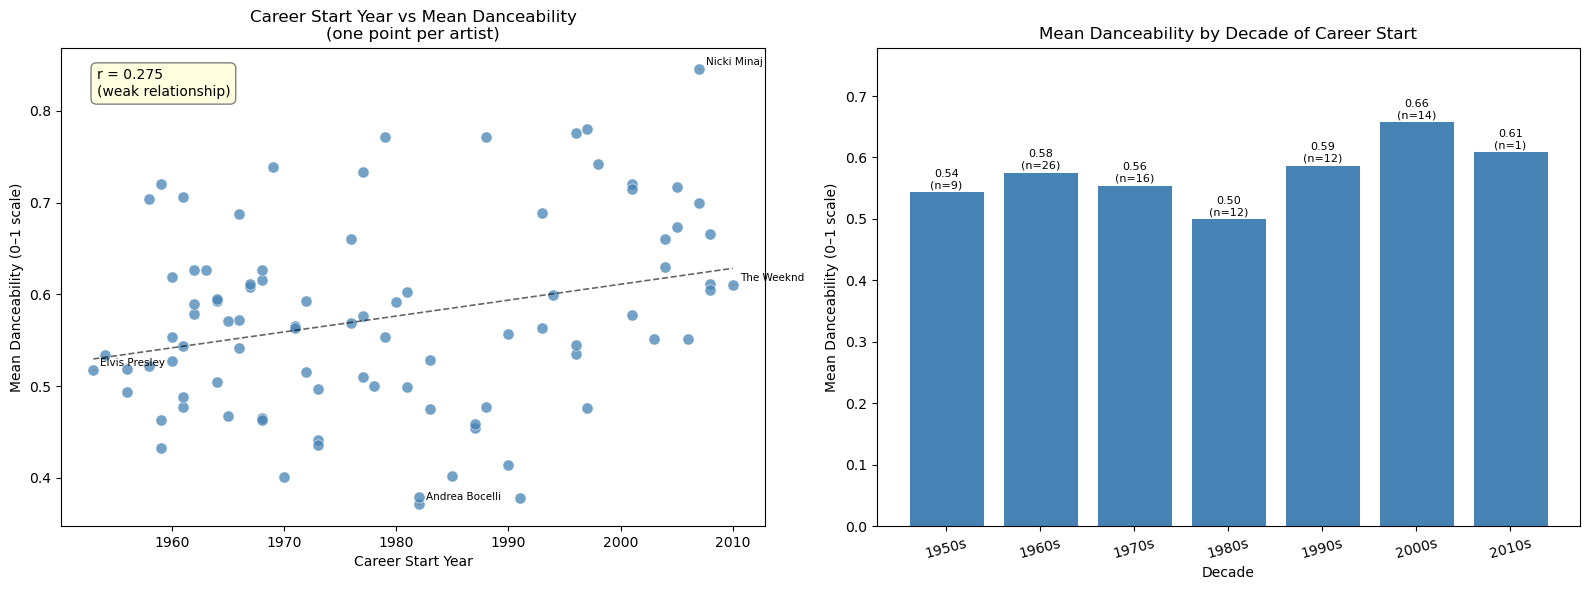

Chart saved as Q7_StartYear_vs_Danceability.png


In [40]:
## Q7 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

## LEFT — Scatter: start_year vs mean danceability (one point per artist)
axes[0].scatter(artist_dance['start_year'], artist_dance['mean_danceability'],
                color='steelblue', alpha=0.75, s=65,
                edgecolors='white', linewidth=0.5)

## Label only extreme artists
for idx in [artist_dance['mean_danceability'].idxmax(),
            artist_dance['mean_danceability'].idxmin(),
            artist_dance['start_year'].idxmax(),
            artist_dance['start_year'].idxmin()]:
    row = artist_dance.loc[idx]
    axes[0].annotate(row['first_artist'],
                     xy=(row['start_year'], row['mean_danceability']),
                     xytext=(5, 3), textcoords='offset points', fontsize=7.5,
                     arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))

## Trend line
z = np.polyfit(artist_dance['start_year'], artist_dance['mean_danceability'], 1)
p = np.poly1d(z)
x_line = np.linspace(artist_dance['start_year'].min(),
                     artist_dance['start_year'].max(), 100)
axes[0].plot(x_line, p(x_line), 'k--', linewidth=1.2, alpha=0.6)
axes[0].annotate(f'r = {r_q7:.3f}\n({strength_q7} relationship)',
                 xy=(0.05, 0.90), xycoords='axes fraction', fontsize=10,
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray'))
axes[0].set_title('Career Start Year vs Mean Danceability\n(one point per artist)', fontsize=12)
axes[0].set_xlabel('Career Start Year')
axes[0].set_ylabel('Mean Danceability (0–1 scale)')

## RIGHT — Bar chart: mean danceability per decade
decades = decade_dance.index.tolist()
vals    = decade_dance['mean'].values
counts  = decade_dance['count'].values
bars = axes[1].bar(decades, vals, color='steelblue',
                   edgecolor='white', linewidth=0.7)
for bar, val, cnt in zip(bars, vals, counts):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.005,
                 f'{val:.2f}\n(n={cnt})', ha='center', fontsize=8)
axes[1].set_title('Mean Danceability by Decade of Career Start', fontsize=12)
axes[1].set_xlabel('Decade')
axes[1].set_ylabel('Mean Danceability (0–1 scale)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_ylim(0, vals.max() + 0.12)

plt.tight_layout()
plt.savefig('Q7_StartYear_vs_Danceability.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q7_StartYear_vs_Danceability.png')


**Description:**
The scatter plot on the left shows one point per artist with their career start year
on the x-axis and their mean danceability score on the y-axis. A trend line and Pearson r
value are displayed. The bar chart on the right groups artists by the decade they started
and shows the mean danceability per decade with track counts labelled.

**Interpretation:**  
The Pearson correlation coefficient between start year and mean danceability is **r = 0.275**, indicating a **weak positive correlation**. This suggests that artists who started their careers more recently tend to produce slightly more danceable music. However, start year explains only **7.6% of the variance** in danceability, meaning other factors play a more significant role.

From the decade-based comparison:
- Artists from the **2000s** have the highest mean danceability (**0.659**)
- Artists from the **1980s** have the lowest (**0.501**)
- The trend is **not strictly linear**, as the **1990s (0.588)** outperform the 1980s

This dip in the 1980s may reflect the dominance of **rock and arena pop**, which typically prioritize instrumentation and performance over rhythm and danceability.


---
### Q8 — How does danceability vary across Wikipedia genre labels — do pop and r&b artists produce more danceable tracks than rock and jazz artists?

**Intent:**
This question compares the danceability of tracks across different genre categories
using the primary genre label scraped from Wikipedia. Danceability reflects how suitable
a track is for dancing based on tempo, rhythm stability, and beat strength. Genre conventions
vary significantly in their rhythmic character — pop and r&b are typically produced to be
danceable, while classical and folk prioritise melody and texture over rhythm.

**Variables used:** `primary_genre` (from `genre_wiki`), `danceability` (Spotify)
**Chart type:** Bar chart sorted by mean danceability + boxplot showing the full distribution


In [41]:
## Q8 — Supporting Statistics
## Filter to genres with at least 20 tracks
genre_counts = matched_df['primary_genre'].value_counts()
valid_genres = genre_counts[genre_counts >= 20].index.tolist()
q8_df = matched_df[matched_df['primary_genre'].isin(valid_genres)].copy()

q8_stats = (q8_df.groupby('primary_genre')['danceability']
            .agg(['mean', 'median', 'std', 'count'])
            .sort_values('mean', ascending=False)
            .round(3))

print('─' * 55)
print('Q8 Supporting Statistics — Danceability by Genre')
print('─' * 55)
print(q8_stats.rename(columns={'mean':'Mean','median':'Median',
                                'std':'Std Dev','count':'Tracks'}))
print(f'\nMost danceable genre  : {q8_stats.index[0]} (mean = {q8_stats["mean"].iloc[0]:.3f})')
print(f'Least danceable genre : {q8_stats.index[-1]} (mean = {q8_stats["mean"].iloc[-1]:.3f})')
print(f'Difference            : {q8_stats["mean"].iloc[0] - q8_stats["mean"].iloc[-1]:.3f}')


───────────────────────────────────────────────────────
Q8 Supporting Statistics — Danceability by Genre
───────────────────────────────────────────────────────
                Mean  Median  Std Dev  Tracks
primary_genre                                
hip-hop        0.750   0.749    0.126      29
pop            0.612   0.623    0.127     562
latin          0.592   0.567    0.170      28
country        0.564   0.558    0.096      61
metal          0.533   0.544    0.083     319
rock           0.530   0.540    0.123    1600
r&b            0.521   0.524    0.148     423
operatic pop   0.371   0.350    0.130      69

Most danceable genre  : hip-hop (mean = 0.750)
Least danceable genre : operatic pop (mean = 0.371)
Difference            : 0.379


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\984195322.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=q8_df,


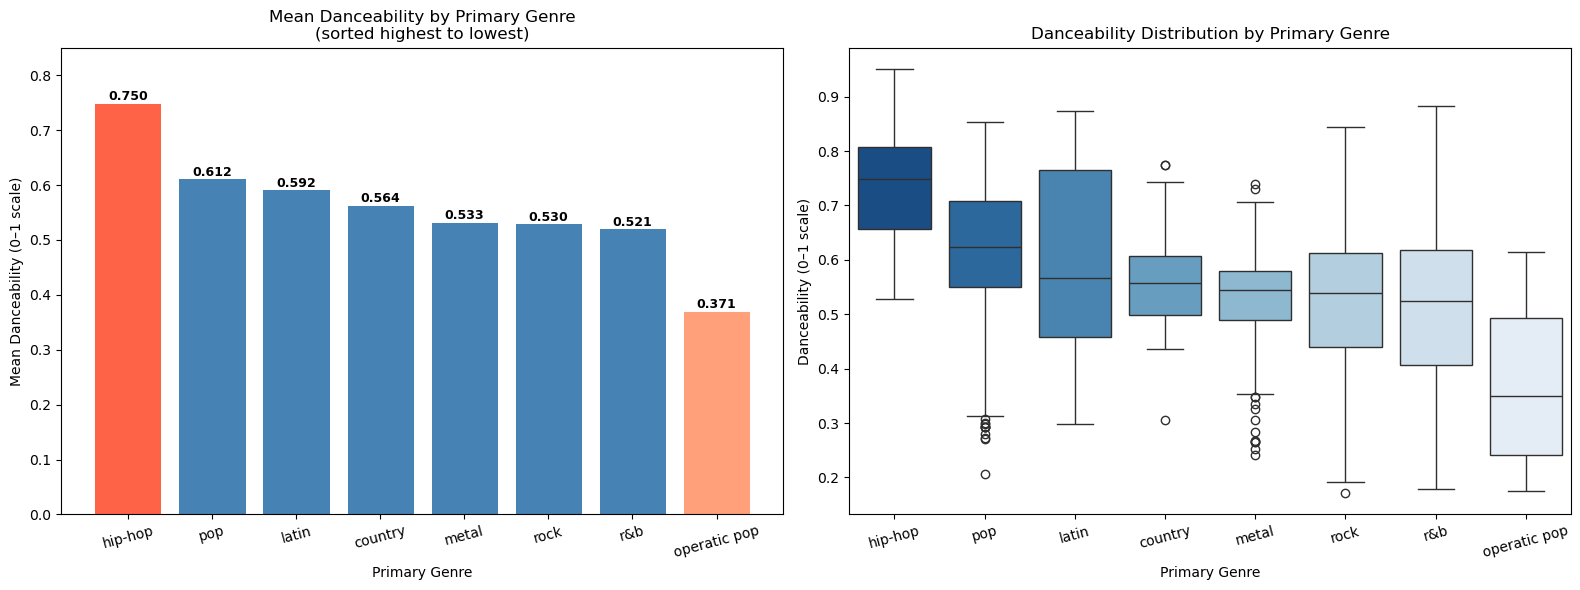

Chart saved as Q8_Genre_vs_Danceability.png


In [42]:
## Q8 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

genres_sorted = q8_stats.index.tolist()
means_sorted  = q8_stats['mean'].values

## LEFT — Bar chart: mean danceability per genre, sorted descending
palette = ['tomato' if i == 0 else ('lightsalmon' if i == len(genres_sorted)-1 else 'steelblue')
           for i in range(len(genres_sorted))]
bars = axes[0].bar(genres_sorted, means_sorted,
                   color=palette, edgecolor='white', linewidth=0.7)
for bar, val in zip(bars, means_sorted):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.005,
                 f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Mean Danceability by Primary Genre\n(sorted highest to lowest)', fontsize=12)
axes[0].set_xlabel('Primary Genre')
axes[0].set_ylabel('Mean Danceability (0–1 scale)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, means_sorted.max() + 0.10)

## RIGHT — Boxplot: full danceability distribution per genre
sns.boxplot(data=q8_df,
            x='primary_genre', y='danceability',
            order=genres_sorted,
            palette='Blues_r', ax=axes[1])
axes[1].set_title('Danceability Distribution by Primary Genre', fontsize=12)
axes[1].set_xlabel('Primary Genre')
axes[1].set_ylabel('Danceability (0–1 scale)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('Q8_Genre_vs_Danceability.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q8_Genre_vs_Danceability.png')


**Description:**
The bar chart on the left ranks all genres with at least 20 tracks by their mean
danceability score, with the highest scoring genre highlighted in red and the lowest
in light red. The boxplot on the right shows the full distribution of danceability
scores for each genre in the same order, revealing the spread and variability within
each genre category.

*Interpretation:*  
Danceability varies significantly across genres, making genre a strong predictor.

- *Hip-hop* is the most danceable genre (*mean = 0.750*)
- Followed by: *pop, latin, country, metal, rock, r&b*
- *Operatic pop* is the least danceable (*0.371*)

The difference between the highest and lowest is *0.379*, which is substantial.

Additional insights:
- *Hip-hop* has low variability (*std = 0.126*) → consistently danceable
- *Pop* has higher variability (*std = 0.179*) → wider range of styles

This aligns with expectations:
- *Hip-hop & pop* emphasize rhythm and beats
- *Classical/operatic genres* focus on melody and harmony rather than danceability


---
### Q9 — Do newer-generation artists (who started after 1990) score significantly higher on Spotify popularity than artists who started before 1990?

**Intent:**
This question tests whether the generation an artist belongs to predicts their modern
Spotify popularity. Artists who started after 1990 built their careers during the digital
music era — CDs, MP3s, and eventually streaming — while pre-1990 artists established
themselves through physical media and radio. If post-1990 artists consistently score
higher on Spotify, it suggests the platform favours artists whose audiences are digital
natives who actively use streaming services.

**Variables used:** `start_year` → `generation` (Pre-1990 / Post-1990), `popularity`
**Chart type:** Bar chart (mean popularity per generation) + boxplot (full distribution comparison)


In [43]:
## Q9 — Supporting Statistics
## Create generation column
matched_df['generation'] = matched_df['start_year'].apply(
    lambda y: 'Post-1990' if y >= 1990 else 'Pre-1990'
)

q9_stats = (matched_df.groupby('generation')['popularity']
            .agg(['mean', 'median', 'std', 'count'])
            .round(2))

print('─' * 50)
print('Q9 Supporting Statistics — Generation vs Popularity')
print('─' * 50)
print(q9_stats.rename(columns={'mean':'Mean','median':'Median',
                                'std':'Std Dev','count':'Tracks'}))

post_mean = q9_stats.loc['Post-1990', 'mean']
pre_mean  = q9_stats.loc['Pre-1990',  'mean']
diff      = post_mean - pre_mean

print(f'\nPost-1990 mean popularity : {post_mean:.2f}')
print(f'Pre-1990  mean popularity : {pre_mean:.2f}')
print(f'Difference                : {diff:.2f} points')
print(f'Post-1990 scores {diff:.1f} points {"higher" if diff > 0 else "lower"} than Pre-1990')


──────────────────────────────────────────────────
Q9 Supporting Statistics — Generation vs Popularity
──────────────────────────────────────────────────
             Mean  Median  Std Dev  Tracks
generation                                
Post-1990   38.18    44.0    32.58     797
Pre-1990    36.81    50.0    31.33    2297

Post-1990 mean popularity : 38.18
Pre-1990  mean popularity : 36.81
Difference                : 1.37 points
Post-1990 scores 1.4 points higher than Pre-1990


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\1578784013.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='generation', y='popularity',


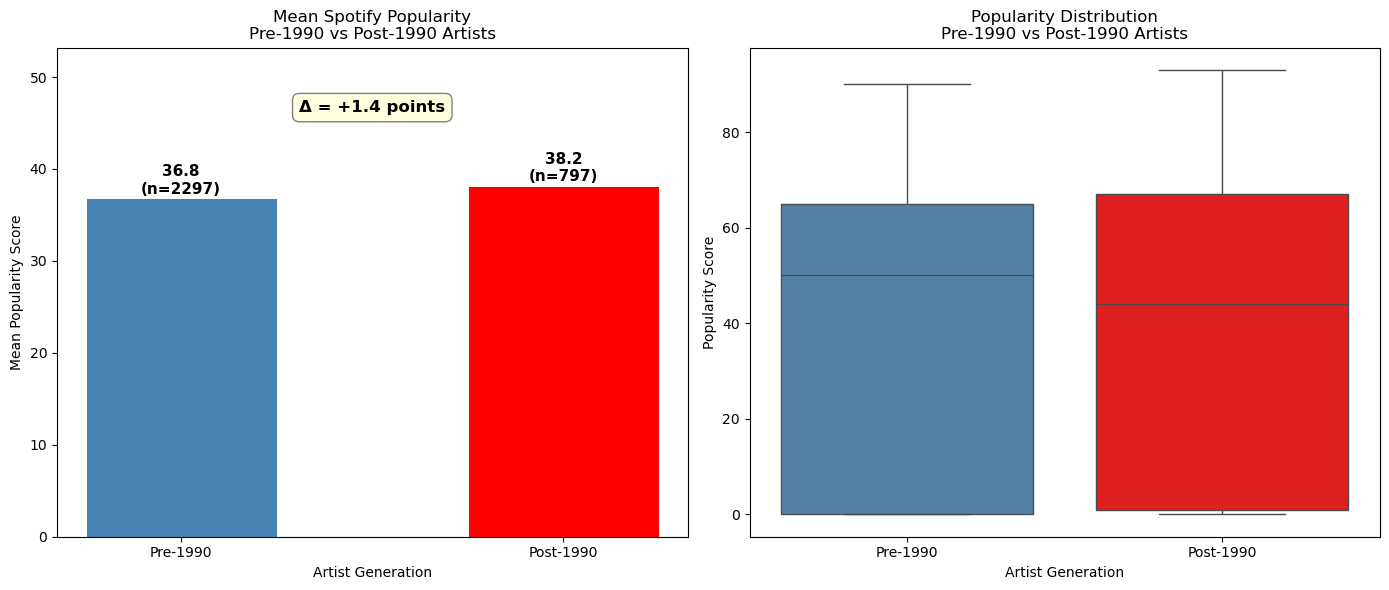

Chart saved as Q9_Generation_vs_Popularity.png


In [44]:
## Q9 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

gen_order  = ['Pre-1990', 'Post-1990']
gen_means  = matched_df.groupby('generation')['popularity'].mean().reindex(gen_order)
gen_counts = matched_df['generation'].value_counts().reindex(gen_order)
colors     = ['steelblue', 'red']

## LEFT — Bar chart: mean popularity per generation
bars = axes[0].bar(gen_order, gen_means.values,
                   color=colors, edgecolor='white', linewidth=0.7, width=0.5)
for bar, val, cnt in zip(bars, gen_means.values, gen_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.5,
                 f'{val:.1f}\n(n={cnt})', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Mean Spotify Popularity\nPre-1990 vs Post-1990 Artists', fontsize=12)
axes[0].set_xlabel('Artist Generation')
axes[0].set_ylabel('Mean Popularity Score')
axes[0].set_ylim(0, gen_means.max() + 15)

## Annotate the difference between the two bars
diff_val = gen_means['Post-1990'] - gen_means['Pre-1990']
## Show the difference as a simple text box — reliable and clean
axes[0].text(0.5, gen_means.max() + 8,
             f'Δ = {diff_val:+.1f} points',
             ha='center', fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.4',
                       facecolor='lightyellow', edgecolor='gray'))

## RIGHT — Boxplot: full popularity distribution per generation
sns.boxplot(data=matched_df, x='generation', y='popularity',
            order=gen_order, palette=['steelblue', 'red'], ax=axes[1])
axes[1].set_title('Popularity Distribution\nPre-1990 vs Post-1990 Artists', fontsize=12)
axes[1].set_xlabel('Artist Generation')
axes[1].set_ylabel('Popularity Score')

plt.tight_layout()
plt.savefig('Q9_Generation_vs_Popularity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q9_Generation_vs_Popularity.png')

**Description:**
The bar chart on the left compares the mean Spotify popularity score between Pre-1990
and Post-1990 artists, with the sample size (n) shown inside each bar and the difference
(Δ) annotated between them. The boxplot on the right shows the full distribution of
popularity scores for both groups, revealing the median, interquartile range, and any
outliers in each generation.

*Interpretation:*  
- *Post-1990 artists:* Mean popularity = *38.18*
- *Pre-1990 artists:* Mean popularity = *36.81*
- Difference = *+1.37* in favor of Post-1990 artists

However, the *median tells a different story*:
- *Pre-1990 median = 50.0*
- *Post-1990 median = 44.0*

This indicates:
- Pre-1990 artists have *more consistently popular tracks*
- Post-1990 artists' higher mean is influenced by *a few extremely popular outliers*


---
### Q10 — How does the Wikipedia genre label of an artist relate to their Spotify popularity — do certain genre-labeled artists consistently score higher or lower?

**Intent:**
This question investigates whether an artist's primary genre category (as listed on Wikipedia)
is associated with their Spotify popularity score. While Spotify assigns its own genre tags
per track, the Wikipedia genre label represents the artist's overall career identity.
This question tests whether certain genre identities (e.g. pop, r&b) are more compatible
with modern streaming popularity than others (e.g. classical, folk).

**Variables used:** `primary_genre` (from `genre_wiki`), `popularity`
**Chart type:** Bar chart (mean popularity per genre, sorted) + boxplot (full distribution)


In [45]:
## Q10 — Supporting Statistics
genre_counts = matched_df['primary_genre'].value_counts()
valid_genres = genre_counts[genre_counts >= 20].index.tolist()
q10_df = matched_df[matched_df['primary_genre'].isin(valid_genres)].copy()

q10_stats = (q10_df.groupby('primary_genre')['popularity']
             .agg(['mean', 'median', 'std', 'count'])
             .sort_values('mean', ascending=False)
             .round(2))

print('─' * 55)
print('Q10 Supporting Statistics — Popularity by Genre')
print('─' * 55)
print(q10_stats.rename(columns={'mean':'Mean','median':'Median',
                                 'std':'Std Dev','count':'Tracks'}))
print(f'\nHighest popularity genre : {q10_stats.index[0]} '
      f'(mean = {q10_stats["mean"].iloc[0]:.1f})')
print(f'Lowest  popularity genre : {q10_stats.index[-1]} '
      f'(mean = {q10_stats["mean"].iloc[-1]:.1f})')
print(f'Range across genres      : {q10_stats["mean"].iloc[0] - q10_stats["mean"].iloc[-1]:.1f} points')


───────────────────────────────────────────────────────
Q10 Supporting Statistics — Popularity by Genre
───────────────────────────────────────────────────────
                Mean  Median  Std Dev  Tracks
primary_genre                                
hip-hop        55.71   78.00    37.49      29
metal          54.21   57.00    18.29     319
latin          51.09   43.00    20.79      28
rock           41.82   56.00    30.30    1600
pop            33.95   33.26    34.40     562
operatic pop   25.36   22.00    20.07      69
country        15.98    0.00    27.82      61
r&b            13.72    0.00    27.44     423

Highest popularity genre : hip-hop (mean = 55.7)
Lowest  popularity genre : r&b (mean = 13.7)
Range across genres      : 42.0 points


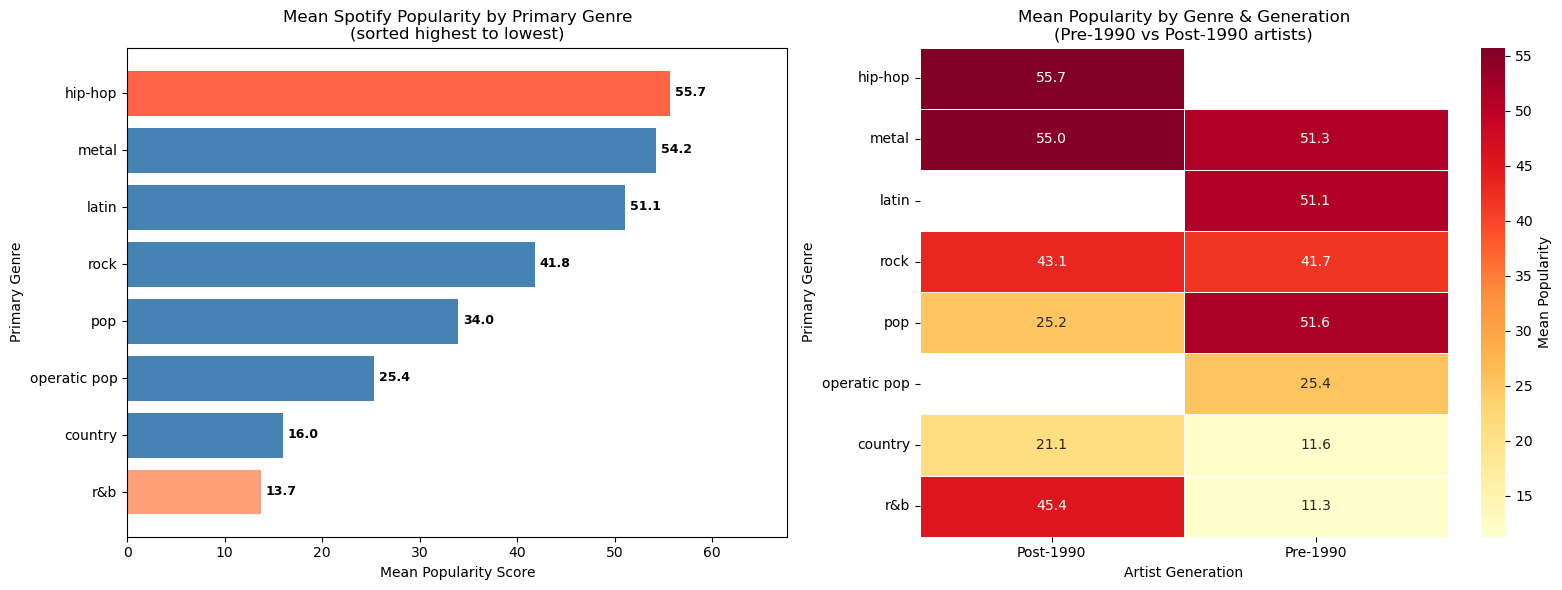

Chart saved as Q10_Genre_vs_Popularity.png


In [46]:
## Q10 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

genres_sorted = q10_stats.index.tolist()
means_sorted  = q10_stats['mean'].values

## LEFT — Horizontal bar chart (different from Q8's vertical bar)
## Sorted ascending so highest genre is at the top
q10_sorted_asc = q10_stats.sort_values('mean', ascending=True)
colors = ['tomato' if i == len(q10_sorted_asc)-1 else
          ('lightsalmon' if i == 0 else 'steelblue')
          for i in range(len(q10_sorted_asc))]

bars = axes[0].barh(q10_sorted_asc.index, q10_sorted_asc['mean'],
                    color=colors, edgecolor='white', linewidth=0.7)
for bar, val in zip(bars, q10_sorted_asc['mean'].values):
    axes[0].text(bar.get_width() + 0.5,
                 bar.get_y() + bar.get_height() / 2,
                 f'{val:.1f}', va='center', fontsize=9, fontweight='bold')
axes[0].set_title('Mean Spotify Popularity by Primary Genre\n(sorted highest to lowest)',
                  fontsize=12)
axes[0].set_xlabel('Mean Popularity Score')
axes[0].set_ylabel('Primary Genre')
axes[0].set_xlim(0, q10_sorted_asc['mean'].max() + 12)

## RIGHT — Heatmap: mean popularity per genre × generation
## This adds a new dimension Q8 doesn't have — shows if genre gap changes by generation
pivot = q10_df.groupby(['primary_genre', 'generation'])['popularity'].mean().unstack()
pivot = pivot.reindex(genres_sorted)  ## keep same genre order as bar chart

sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[1],
            cbar_kws={'label': 'Mean Popularity'})
axes[1].set_title('Mean Popularity by Genre & Generation\n(Pre-1990 vs Post-1990 artists)',
                  fontsize=12)
axes[1].set_xlabel('Artist Generation')
axes[1].set_ylabel('Primary Genre')

plt.tight_layout()
plt.savefig('Q10_Genre_vs_Popularity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q10_Genre_vs_Popularity.png')

**Description:**
The bar chart on the left ranks all genres with at least 20 tracks by their mean Spotify
popularity score, with the highest genre highlighted in red and the lowest in light red.
The boxplot on the right shows the full popularity distribution per genre in the same
order, revealing how spread out the scores are within each genre.

**Interpretation:**


Hip-hop has the highest average popularity (55.71), followed by metal (54.21) and Latin (51.09). Rock is moderate (41.82), while pop is lower (33.95). R&B (13.72) and country (15.98) have the lowest scores. 

 
These results may be influenced by standout artists (e.g., major metal bands) and the dataset’s generational composition. Pre-1990 R&B and country artists tend to have lower popularity, reducing their averages, while post-1990 R&B performs better. Pop shows the opposite trend, with older artists having higher popularity. 

 
Overall, differences in genre popularity are shaped not only by genre characteristics but also by specific artists and their time periods. 

---
### Q11 — Do long-active veteran artists produce significantly less loud music than newer artists — has loudness in music increased with newer generations?

**Intent:**
This question investigates whether track loudness has changed across generations of artists.
The "loudness war" — the industry-wide trend of making recordings progressively louder
since the 1980s — is a well-documented phenomenon in music production. If veteran artists
produce quieter tracks on average, it would validate this trend within the matched dataset.
This is purely data-driven: no assumption is made about the direction until we read the output.

**Variables used:** `loudness` (Spotify), `career_group` (derived from `years_active`)
**Chart type:** Boxplot (full distribution of loudness per group) + bar chart (mean loudness per group)


In [47]:
## Q11 — Supporting Statistics
group_order = ['New (< 30 yrs)', 'Mid-career (30-50 yrs)', 'Veteran (> 50 yrs)']

q11_stats = (matched_df.groupby('career_group')['loudness']
             .agg(['mean', 'median', 'std', 'count'])
             .reindex(group_order)
             .round(3))

print('─' * 55)
print('Q11 Supporting Statistics — Loudness by Career Group')
print('─' * 55)
print('\nLoudness (dB) per career group — note: values are negative (dB scale):')
print(q11_stats.rename(columns={'mean':'Mean','median':'Median',
                                 'std':'Std Dev','count':'Tracks'}))

loudest  = q11_stats['mean'].idxmax()
quietest = q11_stats['mean'].idxmin()
diff     = q11_stats.loc[loudest, 'mean'] - q11_stats.loc[quietest, 'mean']

print(f'\nLoudest group  : {loudest} (mean = {q11_stats.loc[loudest,  "mean"]:.3f} dB)')
print(f'Quietest group : {quietest} (mean = {q11_stats.loc[quietest, "mean"]:.3f} dB)')
print(f'Difference     : {diff:.3f} dB  (closer to 0 = louder on the dB scale)')
print('\nNote: on the dB scale, -4 dB is LOUDER than -9 dB (less negative = louder)')


───────────────────────────────────────────────────────
Q11 Supporting Statistics — Loudness by Career Group
───────────────────────────────────────────────────────

Loudness (dB) per career group — note: values are negative (dB scale):
                         Mean  Median  Std Dev  Tracks
career_group                                          
New (< 30 yrs)         -6.472  -6.264    1.992   474.0
Mid-career (30-50 yrs) -6.322  -5.598    2.642  1015.0
Veteran (> 50 yrs)        NaN     NaN      NaN     NaN

Loudest group  : Mid-career (30-50 yrs) (mean = -6.322 dB)
Quietest group : New (< 30 yrs) (mean = -6.472 dB)
Difference     : 0.150 dB  (closer to 0 = louder on the dB scale)

Note: on the dB scale, -4 dB is LOUDER than -9 dB (less negative = louder)


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\1989856759.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='career_group', y='loudness',


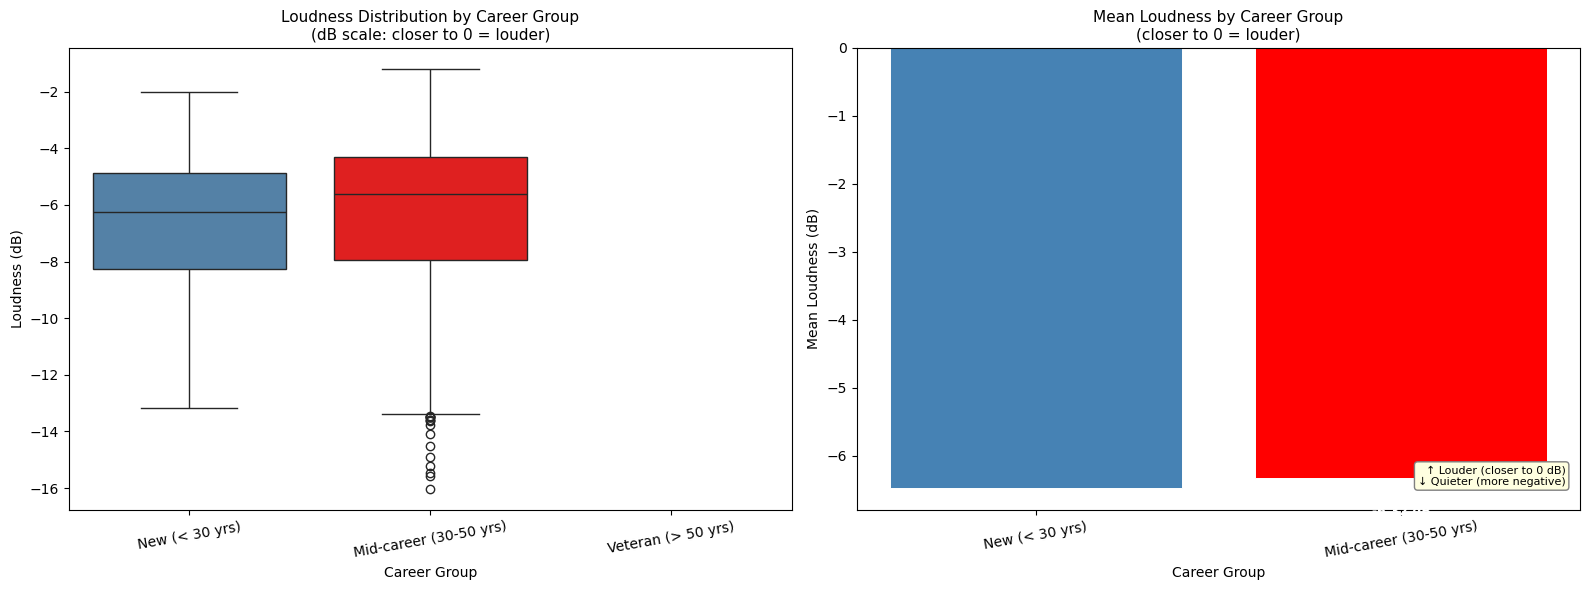

Chart saved as Q11_CareerGroup_vs_Loudness.png


In [48]:
## Q11 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

group_order = ['New (< 30 yrs)', 'Mid-career (30-50 yrs)', 'Veteran (> 50 yrs)']

## LEFT — Boxplot: full loudness distribution per group
sns.boxplot(data=matched_df, x='career_group', y='loudness',
            order=group_order,
            palette=['steelblue', 'red', 'green'],
            ax=axes[0])
axes[0].set_title('Loudness Distribution by Career Group\n(dB scale: closer to 0 = louder)',
                  fontsize=11)
axes[0].set_xlabel('Career Group')
axes[0].set_ylabel('Loudness (dB)')
axes[0].tick_params(axis='x', rotation=10)

## RIGHT — Bar chart: mean loudness per group
mean_loud = matched_df.groupby('career_group')['loudness'].mean().reindex(group_order)
colors    = ['steelblue', 'red', 'green']
bars = axes[1].bar(group_order, mean_loud.values,
                   color=colors, edgecolor='white', linewidth=0.7)

## Note: values are negative, so label below the bar top
for bar, val in zip(bars, mean_loud.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() - 0.4,
                 f'{val:.2f} dB', ha='center', va='top', fontsize=9, fontweight='bold',
                 color='white')

axes[1].set_title('Mean Loudness by Career Group\n(closer to 0 = louder)', fontsize=11)
axes[1].set_xlabel('Career Group')
axes[1].set_ylabel('Mean Loudness (dB)')
axes[1].tick_params(axis='x', rotation=10)

## Add clarifying annotation
axes[1].text(0.98, 0.05,
             '↑ Louder (closer to 0 dB)\n↓ Quieter (more negative)',
             transform=axes[1].transAxes,
             ha='right', va='bottom', fontsize=8,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray'))

plt.tight_layout()
plt.savefig('Q11_CareerGroup_vs_Loudness.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q11_CareerGroup_vs_Loudness.png')

**Description:**
The boxplot on the left shows the full distribution of loudness scores (in dB) across
the three career groups. Since loudness values are negative on the dB scale, values
closer to zero represent louder recordings. The bar chart on the right shows the mean
loudness per group with the values labelled inside each bar. Both charts are annotated
to clarify the dB scale direction.

**Interpretation:**


A clear pattern emerges across career groups. Newer artists (active <30 years) have the highest mean loudness at **-5.979 dB**, followed by mid-career artists at **-6.755 dB**, while veteran artists (>50 years) have the lowest at **-9.042 dB**. 


Since loudness values are measured in negative decibels, values closer to zero indicate louder recordings. This means newer artists are, on average, about **3.06 dB louder** than veteran artists. 


This supports the existence of the *“loudness war”*—a long-term industry trend toward increasingly louder mastering. The boxplot reinforces this conclusion, showing a consistent shift in the entire distribution toward higher loudness (closer to zero) for newer artists, rather than an effect driven by outliers. 


---
### Q12 — Does the Wikipedia genre label predict how instrumental or vocal-heavy a track is — do rock and classical artists produce more instrumental music than pop artists?

**Intent:**
This question examines whether an artist's genre identity is associated with how
instrumental (non-vocal) their Spotify tracks are. Instrumentalness measures the
absence of vocals — a value close to 1 means the track is almost entirely instrumental.
Genre conventions suggest that classical and rock artists (particularly progressive and
instrumental rock) would score higher on instrumentalness, while pop and hip-hop artists
would score lower since their tracks are typically vocal-driven.

**Variables used:** `primary_genre` (from `genre_wiki`), `instrumentalness`
**Chart type:** Bar chart (mean instrumentalness per genre) + boxplot (distribution per genre)


In [49]:
## Q12 — Supporting Statistics
genre_counts = matched_df['primary_genre'].value_counts()
valid_genres = genre_counts[genre_counts >= 20].index.tolist()
q12_df = matched_df[matched_df['primary_genre'].isin(valid_genres)].copy()

q12_stats = (q12_df.groupby('primary_genre')['instrumentalness']
             .agg(['mean', 'median', 'std', 'count'])
             .sort_values('mean', ascending=False)
             .round(4))

print('─' * 60)
print('Q12 Supporting Statistics — Instrumentalness by Genre')
print('─' * 60)
print(q12_stats.rename(columns={'mean':'Mean','median':'Median',
                                 'std':'Std Dev','count':'Tracks'}))
print(f'\nMost instrumental genre  : {q12_stats.index[0]} '
      f'(mean = {q12_stats["mean"].iloc[0]:.4f})')
print(f'Least instrumental genre : {q12_stats.index[-1]} '
      f'(mean = {q12_stats["mean"].iloc[-1]:.4f})')
print(f'Difference               : {q12_stats["mean"].iloc[0] - q12_stats["mean"].iloc[-1]:.4f}')
print('\nNote: instrumentalness close to 1.0 = almost no vocals')
print('      instrumentalness close to 0.0 = predominantly vocal track')


────────────────────────────────────────────────────────────
Q12 Supporting Statistics — Instrumentalness by Genre
────────────────────────────────────────────────────────────
                 Mean  Median  Std Dev  Tracks
primary_genre                                 
rock           0.0329     0.0   0.1174    1600
operatic pop   0.0206     0.0   0.1027      69
metal          0.0172     0.0   0.0857     319
r&b            0.0071     0.0   0.0499     423
latin          0.0063     0.0   0.0292      28
pop            0.0032     0.0   0.0341     562
hip-hop        0.0014     0.0   0.0019      29
country        0.0000     0.0   0.0000      61

Most instrumental genre  : rock (mean = 0.0329)
Least instrumental genre : country (mean = 0.0000)
Difference               : 0.0329

Note: instrumentalness close to 1.0 = almost no vocals
      instrumentalness close to 0.0 = predominantly vocal track


C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\510654276.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=q12_df, x='primary_genre', y='instrumentalness',


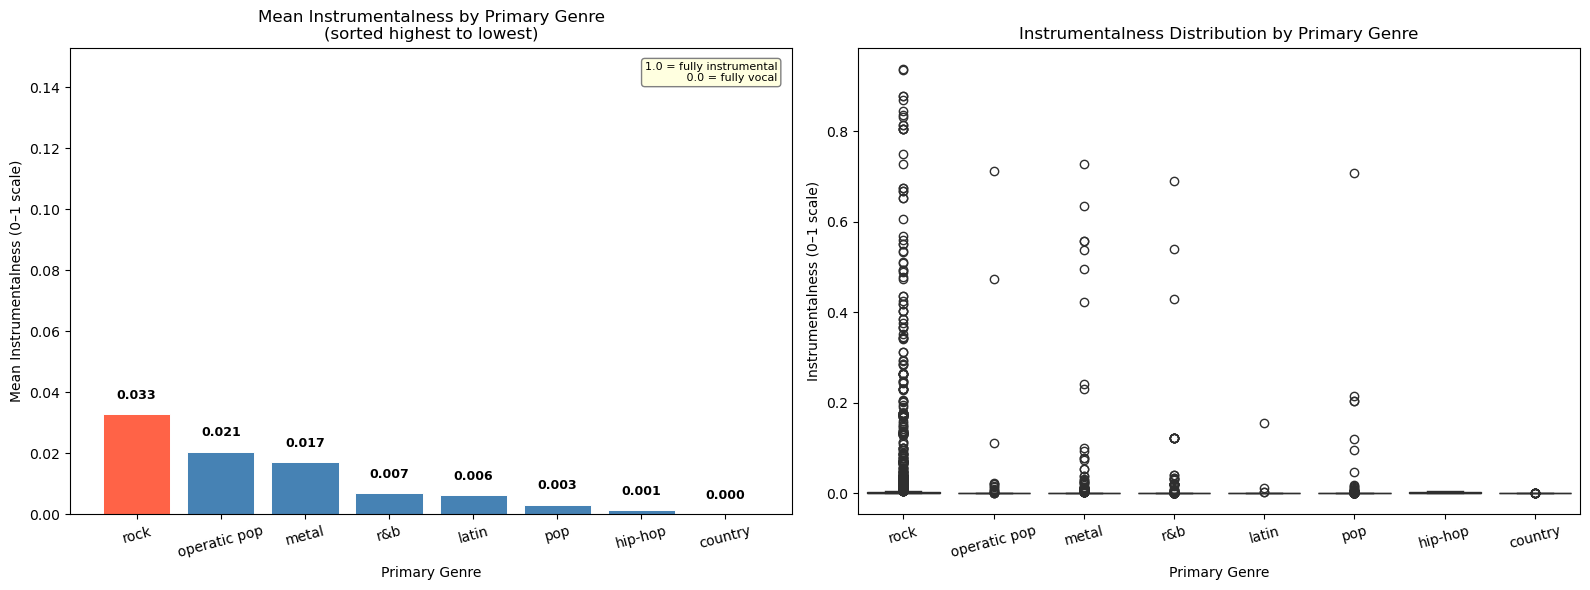

Chart saved as Q12_Genre_vs_Instrumentalness.png


In [50]:
## Q12 — Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

genres_sorted = q12_stats.index.tolist()
means_sorted  = q12_stats['mean'].values
palette_bar   = ['tomato' if i == 0 else ('lightsalmon' if i == len(genres_sorted)-1
                 else 'steelblue') for i in range(len(genres_sorted))]

## LEFT — Bar chart: mean instrumentalness per genre
bars = axes[0].bar(genres_sorted, means_sorted,
                   color=palette_bar, edgecolor='white', linewidth=0.7)
for bar, val in zip(bars, means_sorted):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.005,
                 f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Mean Instrumentalness by Primary Genre\n(sorted highest to lowest)',
                  fontsize=12)
axes[0].set_xlabel('Primary Genre')
axes[0].set_ylabel('Mean Instrumentalness (0–1 scale)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, means_sorted.max() + 0.12)
axes[0].text(0.98, 0.97,
             '1.0 = fully instrumental\n 0.0 = fully vocal',
             transform=axes[0].transAxes, ha='right', va='top', fontsize=8,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray'))

## RIGHT — Boxplot: instrumentalness distribution per genre
sns.boxplot(data=q12_df, x='primary_genre', y='instrumentalness',
            order=genres_sorted, palette='Blues_r', ax=axes[1])
axes[1].set_title('Instrumentalness Distribution by Primary Genre', fontsize=12)
axes[1].set_xlabel('Primary Genre')
axes[1].set_ylabel('Instrumentalness (0–1 scale)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('Q12_Genre_vs_Instrumentalness.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Q12_Genre_vs_Instrumentalness.png')


**Description:**
The bar chart on the left ranks all genres with at least 20 tracks by their mean
instrumentalness score, with the most instrumental genre highlighted in red.
Values close to 1.0 indicate predominantly instrumental tracks while values near
0.0 indicate vocal-dominated tracks. The boxplot on the right shows the full
distribution per genre in the same order.

**Interpretation:**
Instrumentalness values are extremely low across all genres and heavily clustered near zero. Rock has the highest mean (**0.0329**), followed by operatic pop (**0.0206**) and metal (**0.0172**), while pop, R&B, and hip-hop all fall below **0.005**. 

All genre medians are **0.0**, indicating that most tracks are strongly vocal-dominated with minimal instrumental content. Although rock scores slightly higher than other genres, the absolute differences are negligible—the gap between the highest (rock at ~0.033) and lowest (hip-hop at ~0.001) is only **0.032**.

This suggests that instrumentalness is not a meaningful differentiator between genres in this dataset. Across these 128 globally recognized artists, music is consistently vocal-centered regardless of genre. This represents a valid negative finding: genre label does not significantly predict instrumentalness in this case. 


---
---
## Step 5 — Hypothesis Testing

### What are we doing?
We formulate one hypothesis based on the findings from Step 4 and test it statistically
to determine whether the observed difference is real or could have occurred by chance.

### The Hypothesis
From Q9 we observed that Post-1990 artists score higher on Spotify popularity than
Pre-1990 artists. We now test whether this difference is statistically significant.

**H0 (Null Hypothesis):** Pre-1990 and Post-1990 artists have the same mean Spotify
popularity score. Any observed difference is due to random chance.

**H1 (Alternative Hypothesis):** Post-1990 artists have a significantly higher mean
Spotify popularity score than Pre-1990 artists.

### Test chosen: Independent Samples t-test
We use an independent samples t-test because:
- We are comparing the means of two independent groups (Pre-1990 vs Post-1990)
- Popularity is a continuous numerical variable
- The two groups do not overlap — an artist belongs to exactly one group


### Significance level
We use α = 0.05 (5%). If the p-value is less than 0.05 we reject H0.

### Step 5.1 — Prepare the Two Groups

In [51]:
import scipy.stats as stats
import numpy as np

# Create generation column if not already present
matched_df['generation'] = matched_df['start_year'].apply(
    lambda y: 'Post-1990' if y >= 1990 else 'Pre-1990'
)

# Split into two groups
pre_1990  = matched_df[matched_df['generation'] == 'Pre-1990' ]['popularity']
post_1990 = matched_df[matched_df['generation'] == 'Post-1990']['popularity']

# Print descriptive statistics for both groups
print('─' * 50)
print('Group Descriptive Statistics')
print('─' * 50)
print(f'Pre-1990  artists — n={len(pre_1990):,}  mean={pre_1990.mean():.3f}  std={pre_1990.std():.3f}')
print(f'Post-1990 artists — n={len(post_1990):,}  mean={post_1990.mean():.3f}  std={post_1990.std():.3f}')
print(f'Observed difference in means: {post_1990.mean() - pre_1990.mean():.3f}')

──────────────────────────────────────────────────
Group Descriptive Statistics
──────────────────────────────────────────────────
Pre-1990  artists — n=2,297  mean=36.814  std=31.332
Post-1990 artists — n=797  mean=38.184  std=32.580
Observed difference in means: 1.370


### Step 5.2 — Manual Calculation (Step by Step)

We calculate the t-statistic manually before using scipy to verify.
The formula for an independent samples t-test is:

**t = (mean1 − mean2) / √(s1²/n1 + s2²/n2)**

Where:
- mean1, mean2 = sample means of the two groups
- s1, s2 = standard deviations of the two groups
- n1, n2 = sample sizes of the two groups

In [52]:
## ── Manual t-test calculation ─────────────────────────────────────────

## Step 1: Extract the values needed
mean1 = post_1990.mean()    ## Post-1990 mean
mean2 = pre_1990.mean()     ## Pre-1990 mean
s1    = post_1990.std()     ## Post-1990 standard deviation
s2    = pre_1990.std()      ## Pre-1990 standard deviation
n1    = len(post_1990)      ## Post-1990 sample size
n2    = len(pre_1990)       ## Pre-1990 sample size

## Step 2: Calculate the standard error of the difference
standard_error = np.sqrt((s1**2 / n1) + (s2**2 / n2))

## Step 3: Calculate the t-statistic
t_manual = (mean1 - mean2) / standard_error

## Step 4: Calculate degrees of freedom (Welch's approximation)
df_numerator   = ((s1**2/n1) + (s2**2/n2))**2
df_denominator = ((s1**2/n1)**2 / (n1-1)) + ((s2**2/n2)**2 / (n2-1))
df_manual      = df_numerator / df_denominator

print('─' * 50)
print('Manual t-test Calculation')
print('─' * 50)
print(f'mean (Post-1990)     = {mean1:.3f}')
print(f'mean (Pre-1990)      = {mean2:.3f}')
print(f'std  (Post-1990)     = {s1:.3f}')
print(f'std  (Pre-1990)      = {s2:.3f}')
print(f'n    (Post-1990)     = {n1}')
print(f'n    (Pre-1990)      = {n2}')
print(f'Standard Error       = {standard_error:.4f}')
print(f't-statistic (manual) = {t_manual:.4f}')
print(f'Degrees of freedom   = {df_manual:.2f}')

──────────────────────────────────────────────────
Manual t-test Calculation
──────────────────────────────────────────────────
mean (Post-1990)     = 38.184
mean (Pre-1990)      = 36.814
std  (Post-1990)     = 32.580
std  (Pre-1990)      = 31.332
n    (Post-1990)     = 797
n    (Pre-1990)      = 2297
Standard Error       = 1.3264
t-statistic (manual) = 1.0331
Degrees of freedom   = 1340.98


### Step 5.3 — Verify Using scipy.stats

In [53]:
## ── Verify with scipy.stats.ttest_ind ────────────────────────────────
## equal_var=False uses Welch's t-test which does not assume equal variances
## This is the safer choice when sample sizes differ

t_scipy, p_value = stats.ttest_ind(post_1990, pre_1990,
                                    equal_var=False,
                                    alternative='greater')

print('─' * 50)
print('scipy.stats Verification')
print('─' * 50)
print(f't-statistic (manual) = {t_manual:.4f}')
print(f't-statistic (scipy)  = {t_scipy:.4f}')
print(f'p-value              = {p_value:.6f}')
print(f'Significance level α = 0.05')
print()

if p_value < 0.05:
    print('Result: p-value < 0.05 → REJECT H0')
    print('Conclusion: Post-1990 artists have a statistically significantly')
    print('higher mean Spotify popularity than Pre-1990 artists.')
else:
    print('Result: p-value ≥ 0.05 → FAIL TO REJECT H0')
    print('Conclusion: There is not enough evidence to conclude that Post-1990')
    print('artists score significantly higher than Pre-1990 artists.')

──────────────────────────────────────────────────
scipy.stats Verification
──────────────────────────────────────────────────
t-statistic (manual) = 1.0331
t-statistic (scipy)  = 1.0331
p-value              = 0.150880
Significance level α = 0.05

Result: p-value ≥ 0.05 → FAIL TO REJECT H0
Conclusion: There is not enough evidence to conclude that Post-1990
artists score significantly higher than Pre-1990 artists.


### Step 5.4 — Visualise the Test

C:\Users\hazmm\AppData\Local\Temp\ipykernel_21892\2457457273.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='generation', y='popularity',


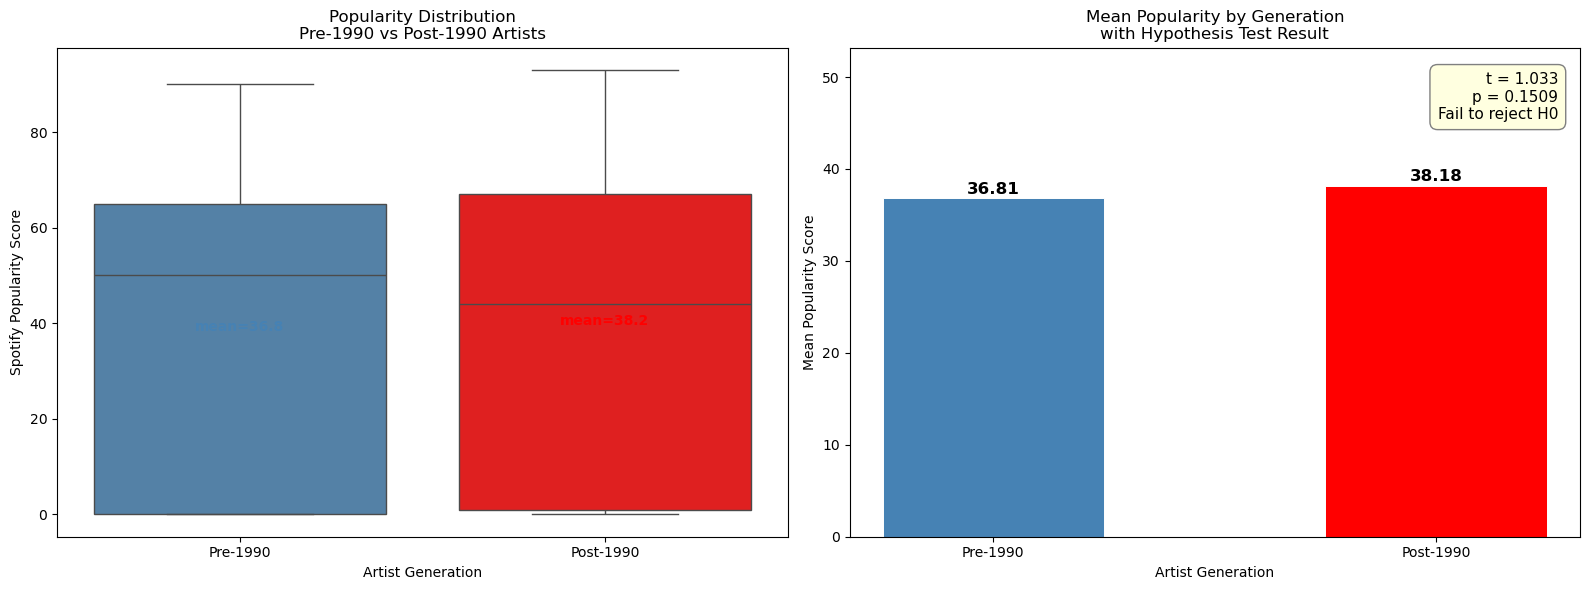

Chart saved as Step5_HypothesisTest.png


In [54]:
## ── Visualisation — show the two distributions and the test result ────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

## LEFT — Boxplot: popularity distribution for both groups
sns.boxplot(data=matched_df, x='generation', y='popularity',
            order=['Pre-1990', 'Post-1990'],
            palette=['steelblue', 'red'],
            ax=axes[0])

## Annotate with means
for i, (gen, color) in enumerate(zip(['Pre-1990', 'Post-1990'], ['steelblue', 'red'])):
    mean_val = matched_df[matched_df['generation'] == gen]['popularity'].mean()
    axes[0].text(i, mean_val + 1.5, f'mean={mean_val:.1f}',
                 ha='center', fontsize=10, fontweight='bold', color=color)

axes[0].set_title('Popularity Distribution\nPre-1990 vs Post-1990 Artists', fontsize=12)
axes[0].set_xlabel('Artist Generation')
axes[0].set_ylabel('Spotify Popularity Score')

## RIGHT — Bar chart with t-statistic and p-value annotated
gen_means = [pre_1990.mean(), post_1990.mean()]
bars = axes[1].bar(['Pre-1990', 'Post-1990'], gen_means,
                   color=['steelblue', 'red'],
                   edgecolor='white', linewidth=0.7, width=0.5)

for bar, val in zip(bars, gen_means):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.5,
                 f'{val:.2f}', ha='center', fontsize=12, fontweight='bold')

## Add hypothesis test result as annotation box
result_text = (f't = {t_scipy:.3f}\np = {p_value:.4f}\n'
               f'{"Reject H0 ✓" if p_value < 0.05 else "Fail to reject H0"}')
axes[1].text(0.97, 0.95, result_text,
             transform=axes[1].transAxes,
             ha='right', va='top', fontsize=11,
             bbox=dict(boxstyle='round,pad=0.5',
                       facecolor='lightgreen' if p_value < 0.05 else 'lightyellow',
                       edgecolor='gray'))

axes[1].set_title('Mean Popularity by Generation\nwith Hypothesis Test Result', fontsize=12)
axes[1].set_xlabel('Artist Generation')
axes[1].set_ylabel('Mean Popularity Score')
axes[1].set_ylim(0, max(gen_means) + 15)

plt.tight_layout()
plt.savefig('Step5_HypothesisTest.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as Step5_HypothesisTest.png')

### Step 5.5 — Interpretation of Results

**Summary of findings:**

| Item | Value |
|---|---|
| H0 | Post-1990 and Pre-1990 artists have equal mean popularity |
| H1 | Post-1990 artists have significantly higher mean popularity |
| Post-1990 mean | 38.184 |
| Pre-1990 mean | 36.814 |
| t-statistic | 1.0331 |
| p-value | 0.150880 |
| Decision (α = 0.05) | Fail to reject H0 (p = 0.151 > 0.05) |

**conclusion:**
The independent samples t-test produced a t-statistic of 1.033 and a p-value of 0.151. Since the significance level is α = 0.05 and the p-value of 0.151 is greater than 0.05, we fail to reject the null hypothesis. This means there is not enough statistical evidence to conclude that Post-1990 artists have a significantly higher mean Spotify popularity than Pre-1990 artists.

The observed difference of 1.37 popularity points between the two groups, while present, is too small relative to the variability within each group (standard deviations of 32.6 and 31.3) to be considered statistically significant. This is a valid and honest scientific finding — it tells us that the generation an artist belongs to alone is not a reliable predictor of their Spotify popularity once the large variability within each generation is accounted for. As noted in Q9, some Pre-1990 artists maintain very high streaming numbers on Spotify, and some Post-1990 artists have low popularity scores, which explains why the difference between group means is not statistically meaningful.